# Task 4: Weather Forecast API and Time-Series EDA
**Region:** Cairo, Egypt (30.0444 °N, 31.2357 °E) · **Period:** 2001-01-01 → 2025-12-31 · **Resolution:** 12 readings a day (every 2 hours) · **Source:** NASA POWER Hourly API

The notebook follows the structure of the brief:

1. **Part 1**: find and query a weather API (availability check, smoke test, 25 yearly pulls, raw + tabular save, API documentation)
2. **Part 2**: prepare the time series (datetime index, frequency/gap/duplicate checks, missing values, reduction to 2-hour blocks, units)
3. **Part 3**: time-series EDA (3.1 descriptive · 3.2 temporal patterns, including the day–night cycle · 3.3 decomposition & stationarity · 3.4 relationships & anomalies)
4. **Written summary**

The API client lives in `fetch_weather.py`. The notebook imports it, so the same code runs from the command line and here.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning

import fetch_weather as fw

warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)  # numpy 2.x timedelta notice raised inside pandas date slicing
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.precision", 2)

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
DATA = Path("data")
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
PER_DAY = 12  # readings per day

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## Part 1: Find and query a weather API

### Choice of API, region and granularity
| Decision | Choice | Why |
|---|---|---|
| **API** | [NASA POWER](https://power.larc.nasa.gov/) Hourly API (`/api/temporal/hourly/point`) | Free and **no API key or registration**. Hourly records for any latitude/longitude from 2001 to the present. It is the first API on the brief's suggested list. |
| **Region** | Cairo, Egypt: 30.0444 °N, 31.2357 °E | A large city with a strong, well-known seasonal cycle, a large day–night swing and a hot desert climate. Rain is rare, which makes precipitation an interesting zero-inflated series. |
| **Range** | **25 full years**, 2001-01-01 → 2025-12-31 | POWER's hourly data **starts on 2001-01-01** (an earlier start date is refused, see 1.1), so 2001 is the earliest possible start. The range ends with 2025, the last complete calendar year, so every year is whole and the data is final (the most recent weeks are provisional). 25 yearly cycles make the trend question answerable and give a forecasting model enough seasons to learn from. |
| **Granularity** | **12 readings a day** (2-hour blocks), built from hourly data | Sub-daily data shows the **day–night cycle**, which daily data hides. 12 divides 24, so readings are evenly spaced (00:00, 02:00 … 22:00); 7 or 10 a day would not be. Hourly data (219,144 rows) would mostly repeat itself, since neighbouring hours are almost identical; 2-hour blocks halve the size and keep the daily peak. |

Requested variables: `T2M` (temperature at 2 m), `PRECTOTCORR` (bias-corrected precipitation), plus the optional extras `RH2M` (relative humidity), `WS2M` (wind speed at 2 m) and `CLOUD_AMT` (cloud cover). The hourly API has no max/min temperature, so the max and min of each 2-hour block (and therefore daily extremes) are derived from the hourly values.

### 1.1 Step 1: confirm the endpoint returns data for Cairo
NASA POWER needs no key, so step 1 here means: (a) check which dates the hourly endpoint serves, and (b) make a small request for our coordinates before the full pull.

In [2]:
# (a) availability: ask for one day in 2000
probe = requests.get(fw.BASE_URL, params=fw.build_params(fw.LATITUDE, fw.LONGITUDE, "20000101", "20000101"), timeout=60)
print("Request for 2000-01-01 -> HTTP", probe.status_code)
print("API message:", probe.json().get("messages"))

Request for 2000-01-01 -> HTTP 422
API message: ['Please provide a correct start date. Your start date out of range. The data starts at 2001/01/01.']


In [3]:
# (b) smoke test: two days of hourly data for Cairo
smoke, smoke_log = fw.fetch_power_hourly(fw.LATITUDE, fw.LONGITUDE, "20010101", "20010102")
print("HTTP status      :", smoke_log["attempts"][-1]["status"])
print("Request URL      :", smoke_log["url"])
print("Point returned   : lon/lat/elev(m) =", smoke["geometry"]["coordinates"])
print("API version      :", smoke["header"]["api"])
fw.to_dataframe(smoke).head(12)

HTTP status      : 200
Request URL      : https://power.larc.nasa.gov/api/temporal/hourly/point?parameters=T2M%2CPRECTOTCORR%2CRH2M%2CWS2M%2CCLOUD_AMT&community=AG&latitude=30.0444&longitude=31.2357&start=20010101&end=20010102&format=JSON&time-standard=LST
Point returned   : lon/lat/elev(m) = [31.236, 30.044, 135.44]
API version      : {'version': 'v2.10.2', 'name': 'POWER Hourly API'}


,datetime,temp,precipitation,humidity,wind_speed,cloud_cover
0,2001010100,9.32,0.0,61.19,1.37,25.02
1,2001010101,9.09,0.0,62.08,1.47,61.26
2,2001010102,8.98,0.0,64.29,1.65,59.96
3,2001010103,7.89,0.0,68.44,1.56,68.78
4,2001010104,7.53,0.0,69.50,1.42,99.07
5,2001010105,7.23,0.0,70.50,1.35,100.00
6,2001010106,6.43,0.0,74.36,1.43,93.58
7,2001010107,7.83,0.0,69.24,1.87,69.49
8,2001010108,11.05,0.0,56.60,3.68,45.96
9,2001010109,13.82,0.0,47.18,3.61,23.98


### 1.2 Steps 2–4: 25 yearly pulls and save the raw responses
`fw.get_data()` makes **one request per calendar year** and writes each response **unchanged** to `data/raw/hourly/nasa_power_cairo_hourly_<year>.json`. One year per request keeps each response small (~0.9 MB) and lets a failed year be retried alone. Later runs reuse the files (`python fetch_weather.py --refresh` forces new downloads), so the analysis doesn't depend on the API being up.

In [4]:
bodies = fw.get_data()
first = bodies[fw.FIRST_YEAR]
print("Years loaded:", min(bodies), "→", max(bodies), f"({len(bodies)} files)")
print("Header (2001):", json.dumps(first["header"]))
print("Raw size on disk: %.1f MB" % (sum(fw.raw_path(y).stat().st_size for y in bodies) / 1e6))

param_table = pd.DataFrame(
    [{"API parameter": k, "column": v, "description": first["parameters"][k]["longname"],
      "units": first["parameters"][k]["units"]} for k, v in fw.PARAMETERS.items()])
param_table

Years loaded: 2001 → 2025 (25 files)
Header (2001): {"title": "NASA/POWER Source Native Resolution Hourly Data", "api": {"version": "v2.10.2", "name": "POWER Hourly API"}, "sources": ["SYN1DEG", "MERRA2", "POWER"], "fill_value": -999.0, "time_standard": "LST", "start": "20010101", "end": "20011231"}
Raw size on disk: 22.2 MB


,API parameter,column,description,units
0,T2M,temp,Temperature at 2 Meters,C
1,PRECTOTCORR,precipitation,Precipitation Corrected,mm/hour
2,RH2M,humidity,Relative Humidity at 2 Meters,%
3,WS2M,wind_speed,Wind Speed at 2 Meters,m/s
4,CLOUD_AMT,cloud_cover,Cloud Amount,%


In [5]:
# Tabular version: one row per hour, NASA's -999 fill value converted to NaN
hourly_raw = fw.hourly_table(bodies)
hourly_raw.to_csv(fw.HOURLY_PATH, index=False)
print(hourly_raw.shape)
hourly_raw.head()

(219144, 6)


,datetime,temp,precipitation,humidity,wind_speed,cloud_cover
0,2001010100,9.32,0.0,61.19,1.37,25.02
1,2001010101,9.09,0.0,62.08,1.47,61.26
2,2001010102,8.98,0.0,64.29,1.65,59.96
3,2001010103,7.89,0.0,68.44,1.56,68.78
4,2001010104,7.53,0.0,69.50,1.42,99.07


### 1.3 Step 5: endpoint, parameters and rate limits
Every request attempt of the full pull is logged to `data/raw/request_log.json` by `fetch_power_hourly`, so the rate-limit statement below records what actually happened.

In [6]:
logs = json.loads(fw.LOG_PATH.read_text())
attempts = pd.DataFrame([a for log in logs for a in log["attempts"]])
print("Endpoint :", fw.BASE_URL)
print("Params   :", json.dumps({k: v for k, v in logs[0]["params"].items() if k not in ("start", "end")}))
print(f"Requests : {len(logs)} (one per year), attempts: {len(attempts)}, "
      f"statuses: {attempts.status.value_counts().to_dict()}")
print(f"Time     : total {attempts.seconds.sum():.0f} s, median {attempts.seconds.median():.1f} s, "
      f"slowest {attempts.seconds.max():.1f} s")
print("Rate-limit headers seen:", sorted({k for h in attempts.rate_limit_headers for k in h}) or "none")
attempts[["start", "end", "status", "seconds"]].head()

Endpoint : https://power.larc.nasa.gov/api/temporal/hourly/point
Params   : {"parameters": "T2M,PRECTOTCORR,RH2M,WS2M,CLOUD_AMT", "community": "AG", "latitude": 30.0444, "longitude": 31.2357, "format": "JSON", "time-standard": "LST"}
Requests : 25 (one per year), attempts: 25, statuses: {200: 25}
Time     : total 82 s, median 2.8 s, slowest 15.5 s
Rate-limit headers seen: none


,start,end,status,seconds
0,20010101,20011231,200,2.66
1,20020101,20021231,200,3.58
2,20030101,20031231,200,2.76
3,20040101,20041231,200,3.29
4,20050101,20051231,200,2.29


**API documentation (step 5)**

| Item | Value |
|---|---|
| Endpoint | `GET https://power.larc.nasa.gov/api/temporal/hourly/point` |
| `parameters` | `T2M,PRECTOTCORR,RH2M,WS2M,CLOUD_AMT` |
| `community` | `AG` (agroclimatology; sets the units to °C, mm/hour, %, m/s) |
| `latitude`, `longitude` | `30.0444`, `31.2357` (central Cairo) |
| `start`, `end` | one calendar year per request: `YYYY0101` → `YYYY1231`, for 2001 … 2025 |
| `format` / `time-standard` | `JSON` / `LST` (local solar time) |
| API key | none required |
| Earliest date served | 2001-01-01 (a request for 2000 returns HTTP 422 with "The data starts at 2001/01/01") |
| Data sources (from header) | MERRA-2 reanalysis (meteorology, precipitation) and CERES SYN1deg (cloud) |

**Rate limits:** the full pull is **25 requests** (one per year), plus the availability probe and a two-day smoke test. All 25 yearly requests returned HTTP 200 on the first attempt, in 82 s in total (median 2.8 s, slowest 15.5 s). No response carried rate-limit headers (`X-RateLimit-*`, `Retry-After`) and no HTTP 429 was returned, so **no rate limit was hit**. The client still waits 1 s between requests, retries with exponential backoff on 429/5xx, and caches every raw response, so re-running the notebook makes only the two small checking calls.

**Something worth noticing already:** the API echoes back an elevation of **135 m**, while central Cairo sits at about 20–25 m. That's because NASA POWER returns the value of a **grid cell** (MERRA-2 is about 0.5° × 0.625°, roughly 50 × 60 km), not a weather station. This matters for precipitation (see 3.4).

## Part 2: Prepare the time-series dataset
### 2.1 Parse dates and set the index
Timestamps are in **local solar time** (`time-standard=LST`, about UTC+2 h 05 min for Cairo's longitude). Unlike Egyptian clock time, solar time never jumps, so Egypt's daylight-saving changes (on and off several times since 2001) cannot create false gaps or duplicated hours.

In [7]:
hourly = hourly_raw.copy()
hourly["datetime"] = pd.to_datetime(hourly["datetime"], format="%Y%m%d%H")
hourly = hourly.set_index("datetime").sort_index()
print(hourly.index.dtype, "| monotonic increasing:", hourly.index.is_monotonic_increasing)
hourly.info()

datetime64[ns] | monotonic increasing: True
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 219144 entries, 2001-01-01 00:00:00 to 2025-12-31 23:00:00
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   temp           219144 non-null  float64
 1   precipitation  219144 non-null  float64
 2   humidity       219144 non-null  float64
 3   wind_speed     219144 non-null  float64
 4   cloud_cover    219144 non-null  float64
dtypes: float64(5)
memory usage: 10.0 MB


### 2.2 Sampling frequency, gaps and duplicated timestamps (hourly)

In [8]:
expected = pd.date_range(hourly.index.min(), hourly.index.max(), freq="h")
checks = pd.Series({
    "inferred frequency": pd.infer_freq(hourly.index[:1000]),
    "first timestamp": hourly.index.min(),
    "last timestamp": hourly.index.max(),
    "expected hours": len(expected),
    "actual rows": len(hourly),
    "missing hours (gaps)": len(expected.difference(hourly.index)),
    "duplicated timestamps": int(hourly.index.duplicated().sum()),
    "distinct step sizes": hourly.index.to_series().diff().dropna().unique().tolist(),
}, name="value").to_frame()
checks

,value
inferred frequency,h
first timestamp,2001-01-01 00:00:00
last timestamp,2025-12-31 23:00:00
expected hours,219144
actual rows,219144
missing hours (gaps),0
duplicated timestamps,0
distinct step sizes,[0 days 01:00:00]


In [9]:
# Defensive: duplicates are averaged and gaps become NaN rows, which the missing-value step then handles explicitly.
hourly = hourly.groupby(level=0).mean().asfreq("h")
assert len(hourly) == len(expected)

### 2.3 Missing values

In [10]:
VARS_H = list(fw.PARAMETERS.values())
fill = first["header"]["fill_value"]
n_fill = sum(v == fill for b in bodies.values() for p in b["properties"]["parameter"].values() for v in p.values())
missing = pd.DataFrame({"missing": hourly[VARS_H].isna().sum(), "% missing": 100 * hourly[VARS_H].isna().mean()})
print("Raw response cells equal to the fill value -999:", n_fill)
missing

Raw response cells equal to the fill value -999: 0


,missing,% missing
temp,0,0.0
precipitation,0,0.0
humidity,0,0.0
wind_speed,0,0.0
cloud_cover,0,0.0


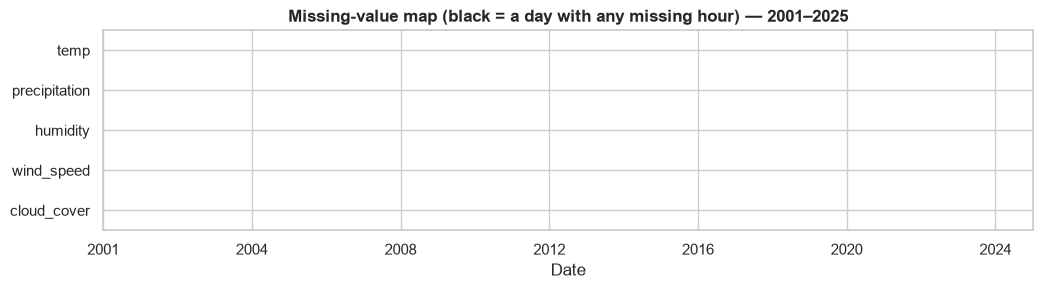

In [11]:
day_missing = hourly[VARS_H].isna().resample("D").max()
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.imshow(day_missing.T.values, aspect="auto", cmap="Greys", vmin=0, vmax=1, interpolation="none",
          extent=[0, len(day_missing), len(VARS_H) - 0.5, -0.5])
ax.set_yticks(range(len(VARS_H)), VARS_H)
ticks = np.arange(0, len(day_missing), 365 * 4)
ax.set_xticks(ticks, [day_missing.index[i].strftime("%Y") for i in ticks])
ax.set_title("Missing-value map (black = a day with any missing hour) — 2001–2025")
ax.set_xlabel("Date")
save(fig, "01_missing_map")

**Missing-value strategy.** It is decided per variable *before* looking at whether anything is actually missing, and it is applied by a function, so a future `--refresh` with gaps is handled the same way. Nothing is dropped. Every filled cell gets a `<column>_imputed` flag.

| Variable(s) | Strategy | Reason |
|---|---|---|
| temperature, humidity, wind speed | **time-based linear interpolation**, gaps ≤ 3 hours | Smooth physical quantities: a short gap is well approximated by its neighbours. Longer gaps stay NaN, because inventing a whole afternoon would distort the day–night cycle. |
| precipitation | **not interpolated**. Single-hour gaps are set to 0 (the overwhelmingly most likely value), longer gaps stay NaN | Rain is intermittent and zero-inflated. Interpolating between a wet hour and a dry hour would create rain that never fell. |
| cloud cover | **forward-fill ≤ 1 hour**, otherwise NaN | Satellite-derived and the series most likely to have gaps; an optional extra, so leaving gaps is acceptable. |

In [12]:
SMOOTH = ["temp", "humidity", "wind_speed"]

def fill_missing(frame):
    out = frame.copy()
    for col in VARS_H:
        out[f"{col}_imputed"] = False
    for col in SMOOTH:
        before = out[col].isna()
        out[col] = out[col].interpolate(method="time", limit=3, limit_area="inside")
        out[f"{col}_imputed"] = before & out[col].notna()
    before = out["precipitation"].isna()
    single = before & ~before.shift(1, fill_value=False) & ~before.shift(-1, fill_value=False)
    out.loc[single, "precipitation"] = 0.0
    out["precipitation_imputed"] = single
    before = out["cloud_cover"].isna()
    out["cloud_cover"] = out["cloud_cover"].ffill(limit=1)
    out["cloud_cover_imputed"] = before & out["cloud_cover"].notna()
    return out

hourly = fill_missing(hourly)
FLAGS_H = [f"{c}_imputed" for c in VARS_H]
print("cells imputed per column:\n", hourly[FLAGS_H].sum().to_string())
print("cells still missing      :", int(hourly[VARS_H].isna().sum().sum()))

cells imputed per column:
 temp_imputed             0
precipitation_imputed    0
humidity_imputed         0
wind_speed_imputed       0
cloud_cover_imputed      0
cells still missing      : 0


**Result:** the API returned a complete hourly series. There are **0 gaps, 0 duplicated timestamps, 0 NaN cells and 0 fill values (-999)** across 219,144 hours and 5 variables, so the strategy above filled nothing (every `_imputed` flag is `False`). The strategy and flags are kept in the pipeline anyway: a pull that reaches the last few weeks before "today" often has trailing -999 values, and they would be handled, and flagged, by the same code.

### 2.4 Reduce to 12 readings a day (2-hour blocks)
Each block covers two hours (00–01, 02–03 … 22–23 local solar time) and is labelled by its start. How each variable is combined depends on what it measures:

| Column | Rule | Why |
|---|---|---|
| `temp_mean`, `humidity`, `wind_speed`, `cloud_cover` | **mean** of the 2 hours | State variables: the block's typical value |
| `temp_max`, `temp_min` | **max / min** of the 2 hours | Keeps the true daily extremes, which a mean would shave off |
| `precipitation` | **sum** of the 2 hours (mm per 2 h) | Rain is an amount: averaging would halve it |

In [13]:
df = fw.to_two_hourly(hourly[VARS_H])
df["any_imputed"] = hourly[FLAGS_H].any(axis=1).resample("2h").max()
VARS = ["temp_mean", "temp_max", "temp_min", "precipitation", "humidity", "wind_speed", "cloud_cover"]

expected_2h = pd.date_range(df.index.min(), df.index.max(), freq="2h")
print("2-hour readings:", len(df), "| expected:", len(expected_2h), "| per day:", set(df.groupby(df.index.date).size()))
print("block start hours:", sorted(df.index.hour.unique()))
print("rain conserved: hourly total %.1f mm vs 2-hour total %.1f mm" % (hourly.precipitation.sum(), df.precipitation.sum()))
print("daily max preserved:", np.allclose(hourly.temp.resample("D").max(), df.temp_max.resample("D").max()))
df[VARS].head(12)

2-hour readings: 109572 | expected: 109572 | per day: {12}
block start hours: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22]
rain conserved: hourly total 1815.6 mm vs 2-hour total 1815.6 mm
daily max preserved: True


,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed,cloud_cover
datetime,,,,,,,
2001-01-01 00:00:00,9.21,9.32,9.09,0.0,61.63,1.42,43.14
2001-01-01 02:00:00,8.44,8.98,7.89,0.0,66.37,1.60,64.37
2001-01-01 04:00:00,7.38,7.53,7.23,0.0,70.00,1.39,99.53
2001-01-01 06:00:00,7.13,7.83,6.43,0.0,71.80,1.65,81.53
2001-01-01 08:00:00,12.44,13.82,11.05,0.0,51.89,3.65,34.97
2001-01-01 10:00:00,18.02,19.40,16.63,0.0,34.76,3.98,0.73
2001-01-01 12:00:00,20.73,20.91,20.56,0.0,25.84,4.35,1.25
2001-01-01 14:00:00,20.15,20.69,19.60,0.0,25.41,3.65,20.48
2001-01-01 16:00:00,13.93,15.28,12.59,0.0,43.60,1.44,46.24


### 2.5 Units and value-range sanity checks

In [14]:
api_units = fw.units(first)
range_checks = pd.DataFrame([
    ("temperature in °C (not °F/K)", "C", api_units["temp"], df["temp_mean"].between(-10, 55).all()),
    ("precipitation: API mm/hour → mm per 2 h after summing", "mm/hour", api_units["precipitation"], (df["precipitation"] >= 0).all()),
    ("humidity in %", "%", api_units["humidity"], df["humidity"].between(0, 100).all()),
    ("wind speed in m/s", "m/s", api_units["wind_speed"], (df["wind_speed"] >= 0).all()),
    ("cloud cover in %", "%", api_units["cloud_cover"], df["cloud_cover"].between(0, 100).all()),
    ("temp_min ≤ temp_mean ≤ temp_max in every block", "-", "-",
     ((df.temp_min <= df.temp_mean + 1e-9) & (df.temp_mean <= df.temp_max + 1e-9)).all()),
], columns=["check", "expected unit", "unit in API metadata", "values plausible"])
range_checks

,check,expected unit,unit in API metadata,values plausible
0,temperature in °C (not °F/K),C,C,True
1,precipitation: API mm/hour → mm per 2 h after ...,mm/hour,mm/hour,True
2,humidity in %,%,%,True
3,wind speed in m/s,m/s,m/s,True
4,cloud cover in %,%,%,True
5,temp_min ≤ temp_mean ≤ temp_max in every block,-,-,True


All units come straight from the response metadata. Temperature is in **°C**, humidity and cloud in **%**, wind in **m/s**, and precipitation arrives in **mm/hour**. After summing two hours it becomes **mm per 2 h**, and daily totals are **mm/day**. The conservation check above confirms that no rain was lost or created by the aggregation (1,815.6 mm in both tables), and that the daily maximum computed from the 2-hour blocks equals the hourly one. The value ranges are physically plausible and `temp_min ≤ temp_mean ≤ temp_max` holds in every block. No conversion was needed.

In [15]:
CLEAN_CSV = DATA / "cairo_weather_2h_clean.csv"
df.to_csv(CLEAN_CSV, index_label="datetime", float_format="%.3f")
print("saved", CLEAN_CSV, df.shape)

# Daily view used for seasonal/annual questions: means of state variables, daily extremes, daily rain total
daily = pd.DataFrame({
    "temp_mean": df.temp_mean.resample("D").mean(),
    "temp_max": df.temp_max.resample("D").max(),
    "temp_min": df.temp_min.resample("D").min(),
    "precipitation": df.precipitation.resample("D").sum(),
    "humidity": df.humidity.resample("D").mean(),
    "wind_speed": df.wind_speed.resample("D").mean(),
    "cloud_cover": df.cloud_cover.resample("D").mean(),
})
print("daily view:", daily.shape)

saved data\cairo_weather_2h_clean.csv (109572, 8)
daily view: (9131, 7)


## Part 3: Exploratory data analysis (time-series focus)
### 3.1 Descriptive overview

In [16]:
UNITS = {"temp_mean": "°C", "temp_max": "°C", "temp_min": "°C", "precipitation": "mm / 2 h",
         "humidity": "%", "wind_speed": "m/s", "cloud_cover": "%"}
desc = df[VARS].describe().T
desc["skew"] = df[VARS].skew()
desc["unit"] = pd.Series(UNITS)
desc

,count,mean,std,min,25%,50%,75%,max,skew,unit
temp_mean,109572.0,21.92,8.64,1.56,15.24,21.59,27.99,45.28,0.18,°C
temp_max,109572.0,22.54,8.74,1.71,15.87,22.15,28.84,45.49,0.15,°C
temp_min,109572.0,21.30,8.56,1.14,14.63,21.04,27.15,45.08,0.22,°C
precipitation,109572.0,0.02,0.33,0.00,0.00,0.00,0.00,46.08,72.69,mm / 2 h
humidity,109572.0,50.94,25.74,3.80,28.38,47.55,72.06,100.00,0.28,%
wind_speed,109572.0,2.86,1.38,0.08,1.70,2.73,3.80,10.18,0.57,m/s
cloud_cover,109572.0,28.28,30.97,0.00,3.47,13.87,47.11,100.00,1.05,%


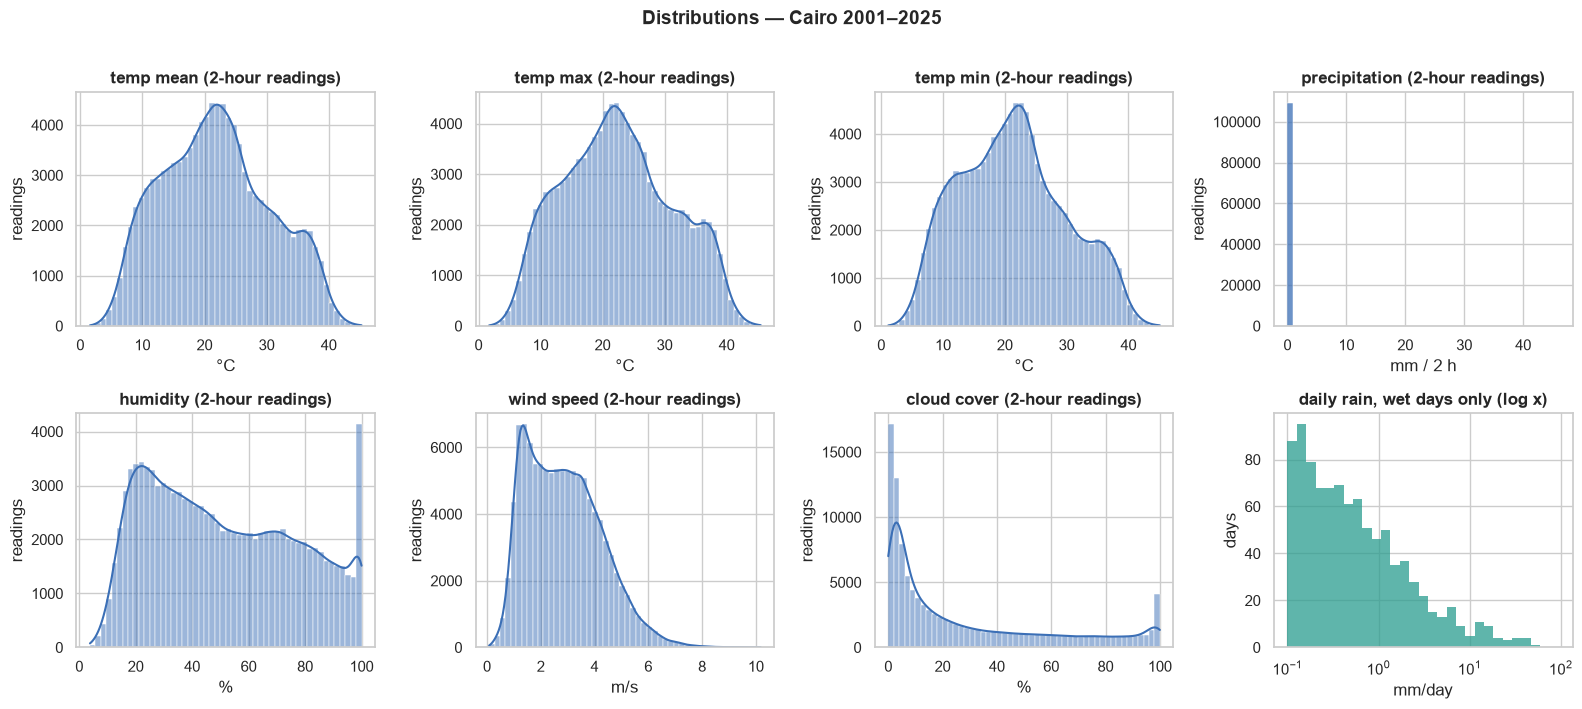

dry 2-hour blocks (< 0.05 mm): 97.0%
dry days (< 0.1 mm): 89.5% | wet days: 956 | median wet-day rain: 0.43 mm


In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, VARS):
    sns.histplot(df[col], kde=col != "precipitation", ax=ax, bins=50, color="#3b6fb6")
    ax.set_title(col.replace("_", " ") + " (2-hour readings)")
    ax.set_xlabel(UNITS[col]); ax.set_ylabel("readings")
wet = daily.loc[daily.precipitation >= 0.1, "precipitation"]
ax = axes.flat[-1]
sns.histplot(wet, bins=np.logspace(-1, np.log10(wet.max()), 30), ax=ax, color="#2a9d8f")
ax.set_xscale("log"); ax.set_title("daily rain, wet days only (log x)")
ax.set_xlabel("mm/day"); ax.set_ylabel("days")
fig.suptitle("Distributions — Cairo 2001–2025", y=1.01, fontsize=14, weight="bold")
fig.tight_layout()
save(fig, "02_distributions")
print(f"dry 2-hour blocks (< 0.05 mm): {(df.precipitation < 0.05).mean():.1%}")
print(f"dry days (< 0.1 mm): {(daily.precipitation < 0.1).mean():.1%} | wet days: {len(wet)} | median wet-day rain: {wet.median():.2f} mm")

**Interpretation**
- **Temperature** across all 2-hour readings averages 21.9 °C (std 8.6 °C, from 1.6 to 45.3 °C). The spread is larger than for daily means because it now includes the day–night swing. The histogram peaks around 22 °C and has a shoulder at 35–40 °C (summer afternoons), with a long cool tail of winter nights.
- **Precipitation** is extremely **zero-inflated**: **97.0 %** of 2-hour blocks and **89.5 %** of days are dry. On the 956 wet days in 25 years, the median is only 0.43 mm, while the wettest 2-hour block holds 46.1 mm. Occurrence (wet/dry) and wet-day amount must be analysed separately.
- **Humidity** ranges from 4 % to 100 %, again because of the day–night cycle. The spike at the 100 % cap (2.8 % of readings) is **saturated air**: all of it falls between 22:00 and 08:00, mostly October–April, at a median of 9.6 °C, which is consistent with dew or fog on cool winter nights. Its frequency is stable across all 25 years.
- **Wind** (mean 2.9 m/s) is right-skewed. **Cloud cover** is mostly clear (median 14 %) with a small overcast spike at 100 %.

#### How hot and how cold: extremes and the day–night swing

In [18]:
swing = daily.temp_max - daily.temp_min
print(f"hottest reading : {daily.temp_max.max():.1f} °C on {daily.temp_max.idxmax().date()}")
print(f"coldest reading : {daily.temp_min.min():.1f} °C on {daily.temp_min.idxmin().date()}")
print(f"mean July max   : {daily.temp_max[daily.index.month == 7].mean():.1f} °C | mean January min: {daily.temp_min[daily.index.month == 1].mean():.1f} °C")
print(f"day–night swing : mean {swing.mean():.1f} °C, widest {swing.max():.1f} °C on {swing.idxmax().date()}")
print("mean swing by month (°C):", swing.groupby(swing.index.month).mean().round(1).to_dict())
yearly_ext = pd.DataFrame({
    "days ≥ 40 °C": (daily.temp_max >= 40).groupby(daily.index.year).sum(),
    "nights ≤ 5 °C": (daily.temp_min <= 5).groupby(daily.index.year).sum(),
    "mean swing (°C)": swing.groupby(daily.index.year).mean().round(1),
}).rename_axis("year")
hot_fit = stats.linregress(yearly_ext.index, yearly_ext["days ≥ 40 °C"])
cold_fit = stats.linregress(yearly_ext.index, yearly_ext["nights ≤ 5 °C"])
print(f"trend in days ≥ 40 °C : {hot_fit.slope*10:+.1f} days/decade (p = {hot_fit.pvalue:.3f})")
print(f"trend in nights ≤ 5 °C: {cold_fit.slope*10:+.1f} nights/decade (p = {cold_fit.pvalue:.3f})")
swing_fit = stats.linregress(yearly_ext.index, yearly_ext["mean swing (°C)"])
print(f"trend in the day–night swing: {swing_fit.slope*10:+.2f} °C/decade (p = {swing_fit.pvalue:.1g})")
yearly_ext.T

hottest reading : 45.5 °C on 2024-06-14
coldest reading : 1.1 °C on 2022-01-25
mean July max   : 38.8 °C | mean January min: 7.0 °C
day–night swing : mean 14.9 °C, widest 24.3 °C on 2005-04-07
mean swing by month (°C): {1: 12.2, 2: 13.3, 3: 15.4, 4: 16.6, 5: 17.1, 6: 17.5, 7: 17.1, 8: 16.4, 9: 15.5, 10: 13.7, 11: 12.5, 12: 11.7}
trend in days ≥ 40 °C : +3.0 days/decade (p = 0.204)
trend in nights ≤ 5 °C: -0.2 nights/decade (p = 0.916)
trend in the day–night swing: -0.30 °C/decade (p = 0.0001)


year,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
days ≥ 40 °C,26.0,33.0,14.0,17.0,13.0,19.0,21.0,19.0,14.0,26.0,...,20.0,21.0,13.0,20.0,20.0,31.0,12.0,36.0,43.0,22.0
nights ≤ 5 °C,8.0,13.0,7.0,9.0,16.0,12.0,8.0,13.0,2.0,3.0,...,16.0,22.0,1.0,14.0,8.0,6.0,21.0,8.0,8.0,2.0
mean swing (°C),15.4,15.2,15.2,15.3,15.1,15.1,15.2,15.2,15.0,15.4,...,14.8,14.5,14.4,14.7,14.6,15.0,14.6,14.5,14.7,15.0


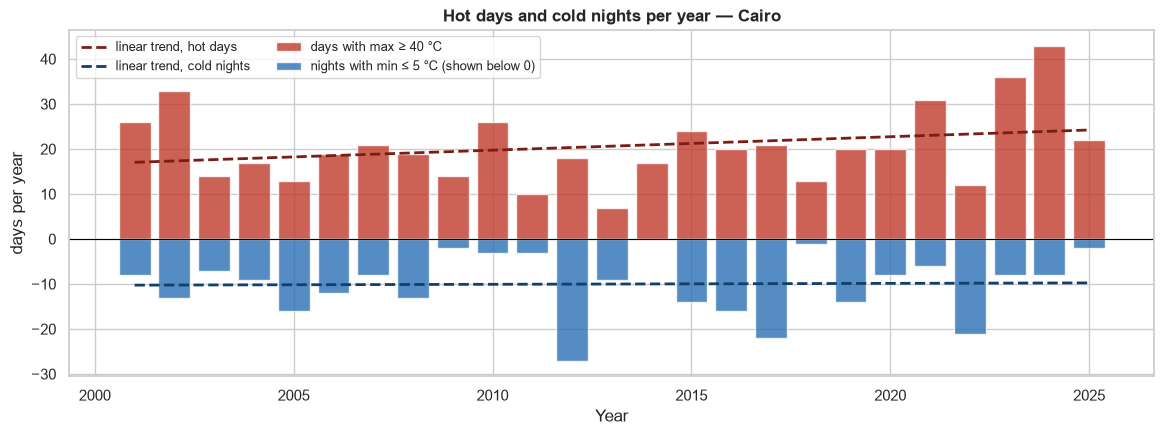

In [19]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(yearly_ext.index, yearly_ext["days ≥ 40 °C"], color="#c0392b", alpha=0.8, label="days with max ≥ 40 °C")
ax.bar(yearly_ext.index, -yearly_ext["nights ≤ 5 °C"], color="#2a6fb6", alpha=0.8, label="nights with min ≤ 5 °C (shown below 0)")
xs = np.array(yearly_ext.index)
ax.plot(xs, hot_fit.intercept + hot_fit.slope * xs, color="#7b1d12", lw=2, ls="--", label="linear trend, hot days")
ax.plot(xs, -(cold_fit.intercept + cold_fit.slope * xs), color="#123f6b", lw=2, ls="--", label="linear trend, cold nights")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Hot days and cold nights per year — Cairo", xlabel="Year", ylabel="days per year")
ax.legend(loc="upper left", ncol=2, fontsize=9)
save(fig, "03_hot_days_cold_nights")

**Interpretation (extremes)**
- The hottest reading was **45.5 °C** (14 June 2024) and the coldest **1.1 °C** (25 January 2022). On average, July afternoons reach 38.8 °C and January nights fall to 7.0 °C.
- The **day–night swing averages 14.9 °C**: about 17 °C in May–July and 12 °C in December–January, because dry, clear desert air heats fast by day and cools fast at night. The widest single swing was 24.3 °C on 7 April 2005.
- **The swing is shrinking: −0.30 °C per decade (p = 0.0001).** Nights are warming faster than days (see the annual trends in 3.2).
- **Days of 40 °C or more** vary a lot (7 to 43 a year, about 21 on average; 2024 had the most). Their linear trend, +3 days per decade, is **not statistically significant** (p = 0.20). Cold nights (≤ 5 °C) show no trend at all (p = 0.92). Extremes are noisier than averages, so 25 years show a direction for the mean but not yet for hot-day counts.

### 3.2 Temporal patterns
#### Full-range line plots
109,572 points in one line are unreadable, so the full range shows **daily** values (mean with the daily min–max band) and daily rain totals.

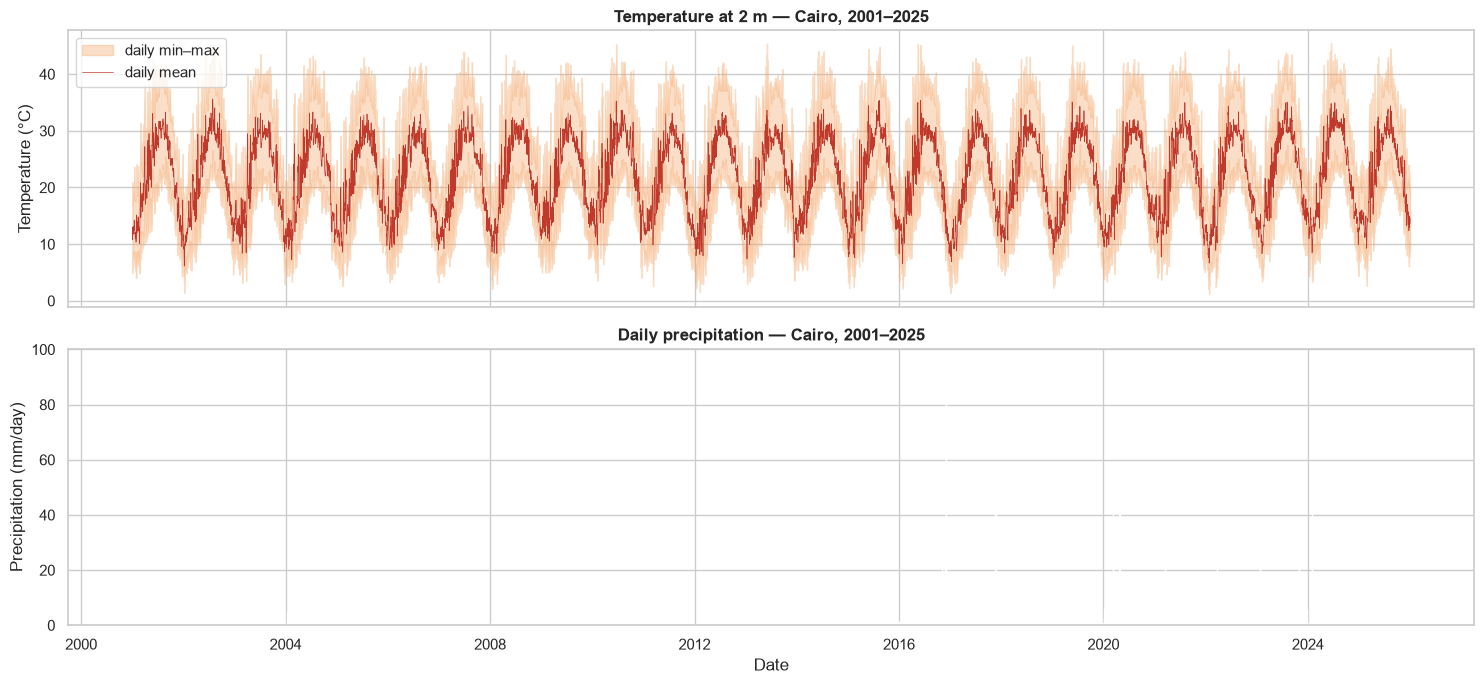

In [20]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
ax1.fill_between(daily.index, daily.temp_min, daily.temp_max, color="#f4a261", alpha=0.35, label="daily min–max")
ax1.plot(daily.index, daily.temp_mean, color="#c0392b", lw=0.5, label="daily mean")
ax1.set_ylabel("Temperature (°C)"); ax1.set_title("Temperature at 2 m — Cairo, 2001–2025"); ax1.legend(loc="upper left")
ax2.bar(daily.index, daily.precipitation, width=1.0, color="#2a6fb6")
ax2.set_ylabel("Precipitation (mm/day)"); ax2.set_title("Daily precipitation — Cairo, 2001–2025"); ax2.set_xlabel("Date")
fig.tight_layout()
save(fig, "04_full_range")

#### Trend: rolling means and annual means

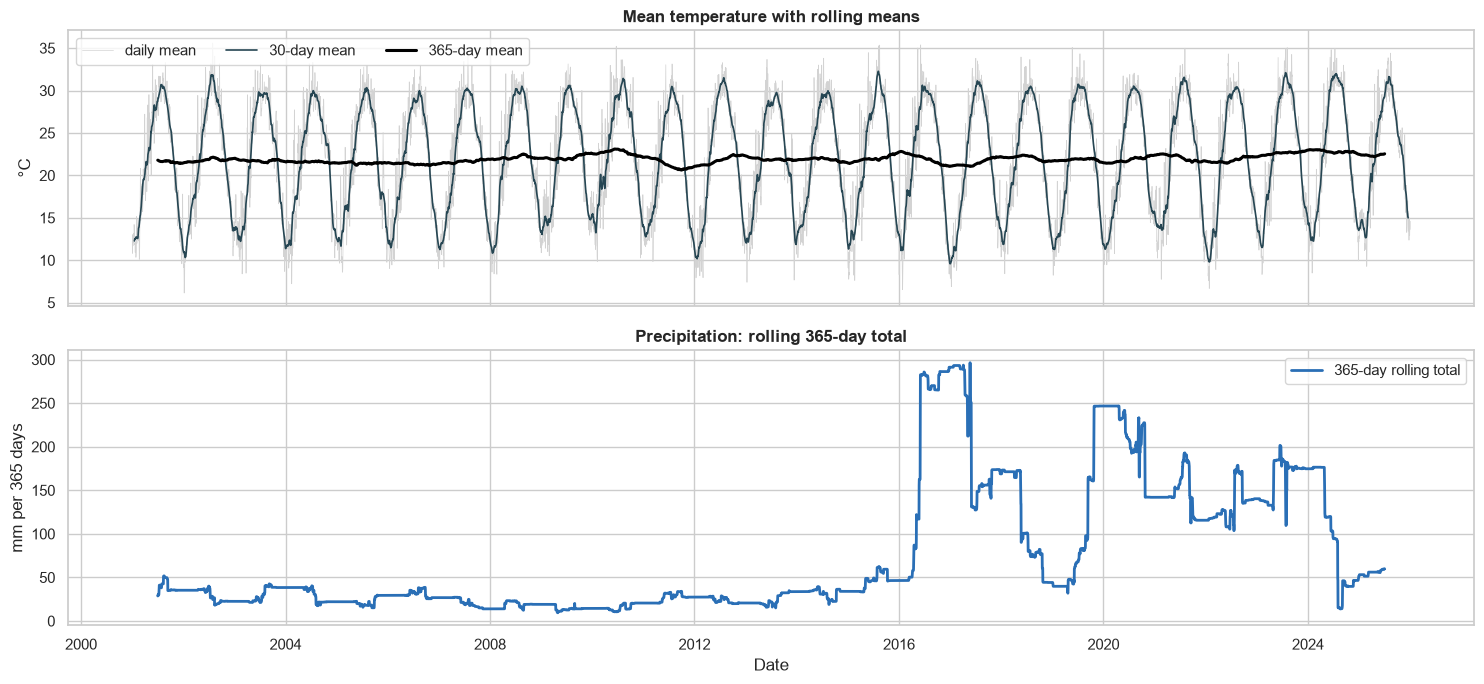

In [21]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
ax1.plot(daily.temp_mean, color="lightgrey", lw=0.5, label="daily mean")
ax1.plot(daily.temp_mean.rolling(30, center=True).mean(), color="#264653", lw=1.2, label="30-day mean")
ax1.plot(daily.temp_mean.rolling(365, center=True).mean(), color="black", lw=2.2, label="365-day mean")
ax1.set_ylabel("°C"); ax1.set_title("Mean temperature with rolling means"); ax1.legend(ncol=3, loc="upper left")
ax2.plot(daily.precipitation.rolling(365, center=True).sum(), color="#2a6fb6", lw=2, label="365-day rolling total")
ax2.set_ylabel("mm per 365 days"); ax2.set_title("Precipitation: rolling 365-day total"); ax2.set_xlabel("Date"); ax2.legend(loc="upper right")
fig.tight_layout()
save(fig, "05_rolling_trend")

In [22]:
annual = pd.DataFrame({
    "mean temp (°C)": daily.temp_mean.resample("YE").mean(),
    "mean daily max (°C)": daily.temp_max.resample("YE").mean(),
    "mean daily min (°C)": daily.temp_min.resample("YE").mean(),
    "total rain (mm)": daily.precipitation.resample("YE").sum(),
    "wet days": (daily.precipitation >= 0.1).resample("YE").sum(),
})
annual.index = annual.index.year

def trend_with_ci(series):
    fit = stats.linregress(series.index, series.values)
    t = stats.t.ppf(0.975, len(series) - 2)
    return fit.slope * 10, t * fit.stderr * 10, fit.pvalue, fit.rvalue ** 2

trend_rows = []
for col in ["mean temp (°C)", "mean daily max (°C)", "mean daily min (°C)", "total rain (mm)"]:
    s, ci, p, r2 = trend_with_ci(annual[col])
    trend_rows.append({"series": col, "slope per decade": s, "95% CI ±": ci, "p-value": p, "R²": r2})
tau, p_mk = stats.kendalltau(annual.index, annual["mean temp (°C)"])
tau_r, p_mk_r = stats.kendalltau(annual.index, annual["total rain (mm)"])
print(f"Mann–Kendall-style rank test: temperature τ = {tau:.2f} (p = {p_mk:.2g}); rain τ = {tau_r:.2f} (p = {p_mk_r:.2g})")
print("first 5 years mean %.2f °C | last 5 years mean %.2f °C" % (annual["mean temp (°C)"].iloc[:5].mean(), annual["mean temp (°C)"].iloc[-5:].mean()))
display(pd.DataFrame(trend_rows).set_index("series"))
annual.T

Mann–Kendall-style rank test: temperature τ = 0.33 (p = 0.022); rain τ = 0.43 (p = 0.002)
first 5 years mean 21.66 °C | last 5 years mean 22.34 °C


,slope per decade,95% CI ±,p-value,R²
series,,,,
mean temp (°C),0.28,0.24,2.71e-02,0.20
mean daily max (°C),0.13,0.29,3.66e-01,0.04
mean daily min (°C),0.42,0.22,6.51e-04,0.40
total rain (mm),59.58,33.31,1.18e-03,0.37


datetime,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
mean temp (°C),21.79,21.86,21.68,21.58,21.40,21.31,21.74,22.07,21.90,23.10,...,21.99,21.31,22.33,21.92,21.74,22.24,21.67,22.67,22.60,22.54
mean daily max (°C),29.99,30.00,29.76,29.78,29.49,29.40,29.85,30.19,29.87,31.41,...,29.96,29.12,30.04,29.81,29.57,30.32,29.43,30.48,30.47,30.53
mean daily min (°C),14.59,14.80,14.58,14.51,14.40,14.34,14.66,14.99,14.87,16.00,...,15.13,14.60,15.65,15.07,14.97,15.28,14.86,15.98,15.76,15.56
total rain (mm),28.74,40.05,21.50,37.59,18.55,33.97,19.21,23.11,12.70,11.32,...,283.91,127.38,101.02,67.86,208.31,161.39,122.72,185.96,94.51,59.82
wet days,36.00,39.00,40.00,31.00,24.00,30.00,28.00,26.00,16.00,12.00,...,44.00,34.00,54.00,37.00,57.00,66.00,66.00,58.00,37.00,39.00


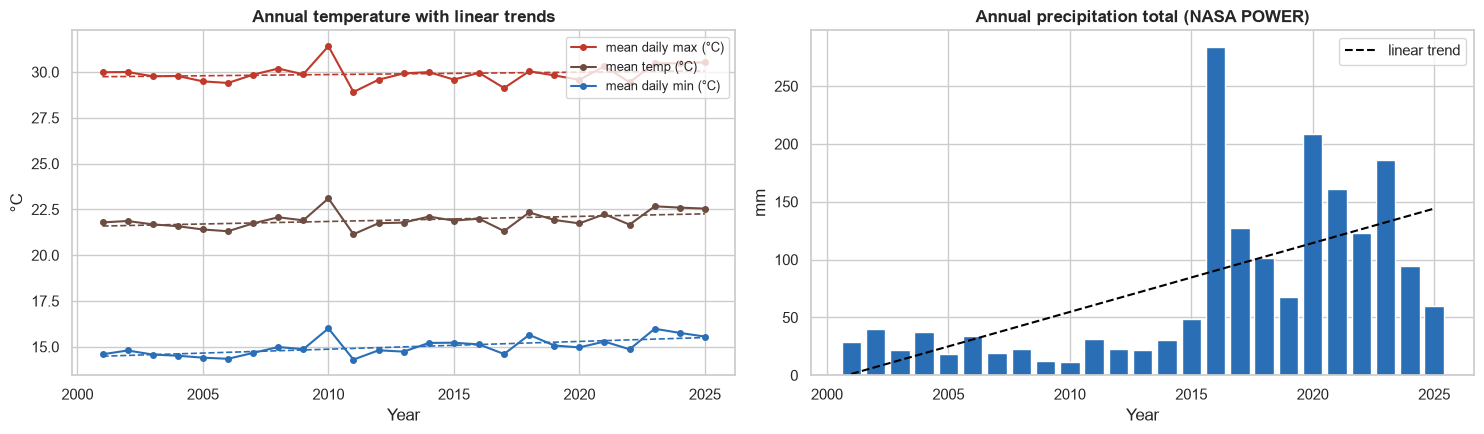

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
yrs = np.array(annual.index)
for col, color in [("mean daily max (°C)", "#c0392b"), ("mean temp (°C)", "#6d4c41"), ("mean daily min (°C)", "#2a6fb6")]:
    fit = stats.linregress(yrs, annual[col])
    ax1.plot(yrs, annual[col], "o-", color=color, ms=4, label=col)
    ax1.plot(yrs, fit.intercept + fit.slope * yrs, "--", color=color, lw=1.2)
ax1.set(title="Annual temperature with linear trends", xlabel="Year", ylabel="°C"); ax1.legend(fontsize=9)
fit = stats.linregress(yrs, annual["total rain (mm)"])
ax2.bar(yrs, annual["total rain (mm)"], color="#2a6fb6")
ax2.plot(yrs, fit.intercept + fit.slope * yrs, "--", color="black", lw=1.5, label="linear trend")
ax2.set(title="Annual precipitation total (NASA POWER)", xlabel="Year", ylabel="mm"); ax2.legend()
fig.tight_layout()
save(fig, "06_annual_trend")

**Interpretation (trend)**
- The 365-day rolling mean removes the seasonal cycle and shows a **slow rise** with year-to-year wiggles. 2010 stands out as the warmest single year (23.1 °C) and 2011 as the coolest (21.1 °C).
- **Mean temperature rose by +0.28 °C per decade (95 % CI ±0.24, p = 0.03)**, and the rank-based Mann–Kendall test agrees (τ = 0.33, p = 0.02). The last five years averaged 22.3 °C against 21.7 °C for the first five. Unlike the 6-year analysis, **25 years are enough to detect this warming with statistical confidence**, though the confidence interval is still wide.
- The warming is **uneven between day and night**: daily minimum temperatures rose by **+0.42 °C/decade** (p < 0.001, R² = 0.40), while daily maximums rose by only +0.13 °C/decade, which is not significant (p = 0.37). Warmer nights are a typical signature of urban growth and of rising humidity and greenhouse gases.
- **Precipitation appears to rise by +60 mm per decade (p = 0.001), but this is not a climate trend.** It is driven by a break in the rain record in 2016 (see "homogeneity check" in 3.4): annual totals jump from about 23 mm to about 125 mm in a single year.

#### Seasonality: distributions by month and season

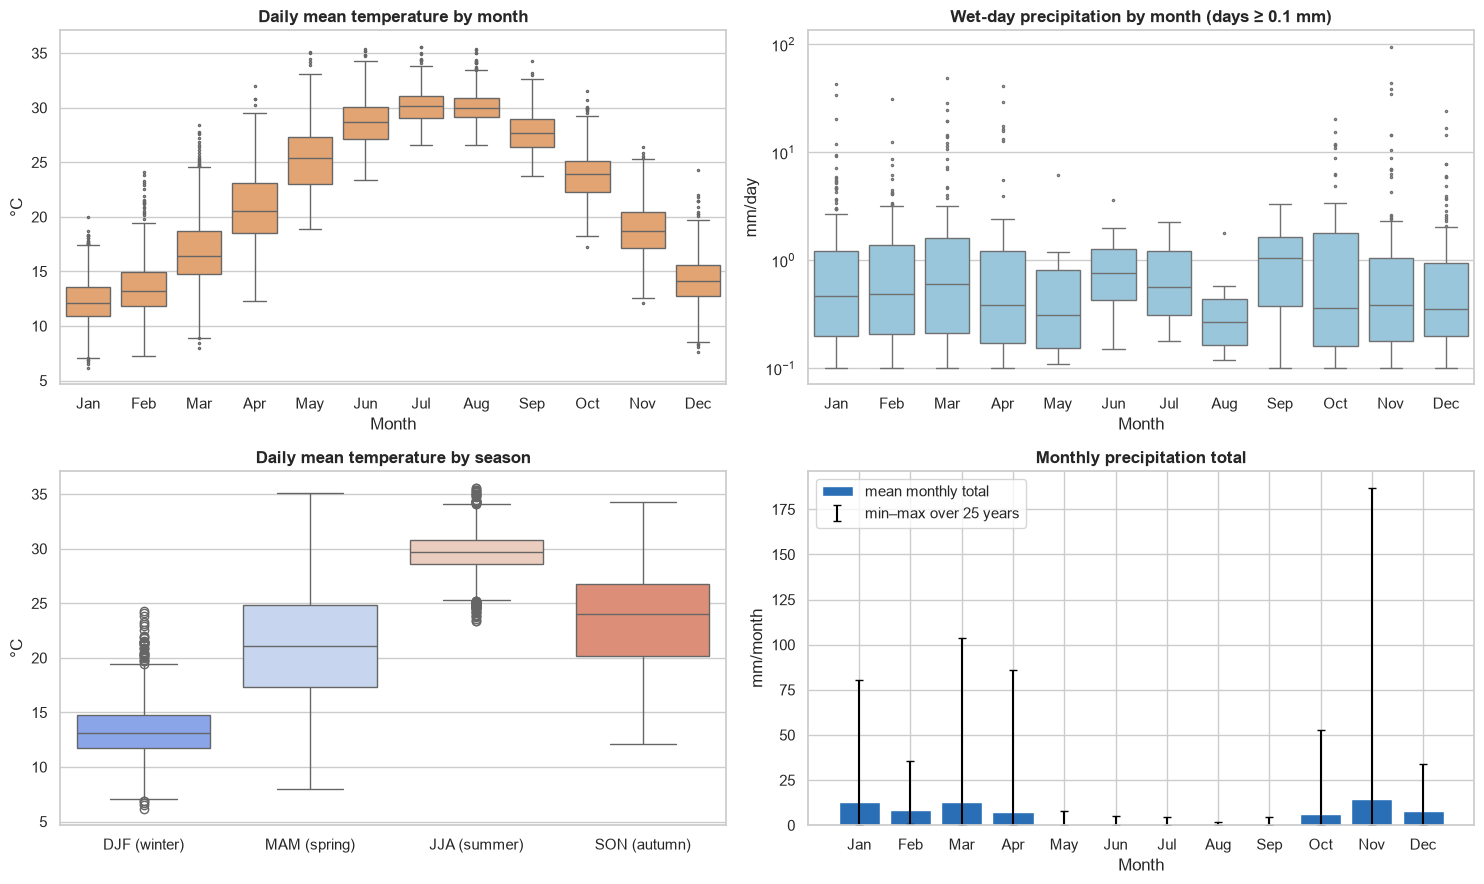

             temp_mean       precipitation       humidity       
                  mean   std          mean   std     mean    std
season                                                          
DJF (winter)     13.34  2.53          0.32  1.78    61.07  13.35
MAM (spring)     21.11  4.75          0.23  2.04    45.56  12.42
JJA (summer)     29.65  1.87          0.01  0.13    42.31   6.33
SON (autumn)     23.45  4.17          0.23  2.65    55.06   9.45
mean monthly temperature (°C): {1: 12.3, 2: 13.6, 3: 16.9, 4: 21.0, 5: 25.4, 6: 28.7, 7: 30.2, 8: 30.1, 9: 27.7, 10: 23.8, 11: 18.9, 12: 14.2}
mean monthly rain (mm): {1: 12.9, 2: 8.5, 3: 13.1, 4: 7.5, 5: 0.7, 6: 0.4, 7: 0.4, 8: 0.1, 9: 0.5, 10: 6.1, 11: 14.6, 12: 7.8}


In [24]:
daily["month"] = daily.index.month
season_map = {12: "DJF (winter)", 1: "DJF (winter)", 2: "DJF (winter)", 3: "MAM (spring)", 4: "MAM (spring)", 5: "MAM (spring)",
              6: "JJA (summer)", 7: "JJA (summer)", 8: "JJA (summer)", 9: "SON (autumn)", 10: "SON (autumn)", 11: "SON (autumn)"}
daily["season"] = daily.month.map(season_map)
ORDER = ["DJF (winter)", "MAM (spring)", "JJA (summer)", "SON (autumn)"]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
sns.boxplot(data=daily, x="month", y="temp_mean", ax=axes[0, 0], color="#f4a261", fliersize=1.5)
axes[0, 0].set(title="Daily mean temperature by month", xlabel="Month", ylabel="°C"); axes[0, 0].set_xticks(range(12), MONTHS)
sns.boxplot(data=daily[daily.precipitation >= 0.1], x="month", y="precipitation", ax=axes[0, 1], color="#8ecae6",
            fliersize=1.5, order=range(1, 13))
axes[0, 1].set(title="Wet-day precipitation by month (days ≥ 0.1 mm)", xlabel="Month", ylabel="mm/day", yscale="log")
axes[0, 1].set_xticks(range(12), MONTHS)
sns.boxplot(data=daily, x="season", y="temp_mean", order=ORDER, ax=axes[1, 0], palette="coolwarm", hue="season", legend=False)
axes[1, 0].set(title="Daily mean temperature by season", xlabel="", ylabel="°C")
monthly_rain = daily.precipitation.resample("ME").sum()
mr = monthly_rain.groupby(monthly_rain.index.month).agg(["mean", "min", "max"])
axes[1, 1].bar(range(12), mr["mean"], color="#2a6fb6", label="mean monthly total")
axes[1, 1].errorbar(range(12), mr["mean"], yerr=[mr["mean"] - mr["min"], mr["max"] - mr["mean"]],
                    fmt="none", ecolor="black", capsize=3, label="min–max over 25 years")
axes[1, 1].set_xticks(range(12), MONTHS); axes[1, 1].legend()
axes[1, 1].set(title="Monthly precipitation total", xlabel="Month", ylabel="mm/month")
fig.tight_layout()
save(fig, "07_seasonality_boxplots")
print(daily.groupby("season")[["temp_mean", "precipitation", "humidity"]].agg(["mean", "std"]).loc[ORDER])
print("mean monthly temperature (°C):", daily.temp_mean.groupby(daily.month).mean().round(1).to_dict())
print("mean monthly rain (mm):", mr["mean"].round(1).to_dict())

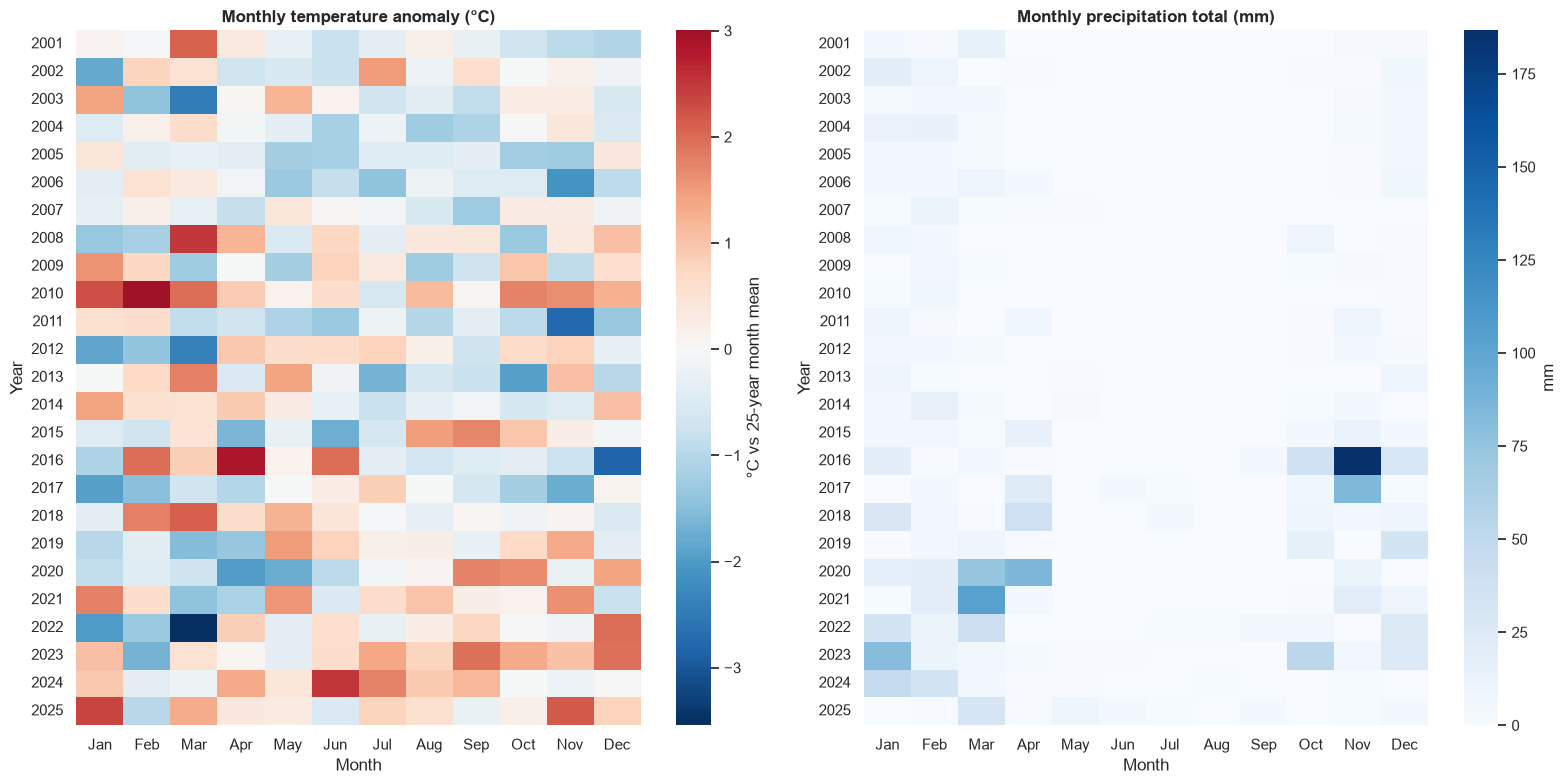

In [25]:
pivot_t = daily.pivot_table(index=daily.index.year, columns="month", values="temp_mean", aggfunc="mean")
pivot_r = daily.pivot_table(index=daily.index.year, columns="month", values="precipitation", aggfunc="sum")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
sns.heatmap(pivot_t - pivot_t.mean(), cmap="RdBu_r", center=0, ax=ax1, cbar_kws={"label": "°C vs 25-year month mean"}, xticklabels=MONTHS)
ax1.set(title="Monthly temperature anomaly (°C)", xlabel="Month", ylabel="Year")
sns.heatmap(pivot_r, cmap="Blues", ax=ax2, cbar_kws={"label": "mm"}, xticklabels=MONTHS)
ax2.set(title="Monthly precipitation total (mm)", xlabel="Month", ylabel="Year")
fig.tight_layout()
save(fig, "08_year_month_heatmap")

**Interpretation (seasonality)**
- **Temperature has a very regular single-peak annual cycle.** January is coldest (mean 12.3 °C) and July warmest (30.2 °C), a range of about 18 °C. The anomaly heatmap shows each month's deviation from its 25-year average; single warm or cold months are scattered across the record, and the warming trend appears as a shift of the whole cycle (the 5-year table in 3.3: 21.6 °C in 2001–05, 22.3 °C in 2021–25).
- The **spread differs by season**: summer is very stable (std 1.9 °C), winter moderately variable (2.5 °C), and **spring (4.8 °C) and autumn (4.2 °C)** have the widest boxes, because they include the steep seasonal transition plus spring hot-wind (*khamsin*) spikes.
- **Rain is strictly seasonal:** practically all of it falls from **October to April**, while May–September averages under 1 mm a month. Over 25 years the wettest months on average are November (14.6 mm), March (13.1 mm) and January (12.9 mm). The year × month rain heatmap also makes the post-2016 jump visible.
- **Humidity** follows the opposite pattern to temperature: about 61 % on average in winter and 42 % in summer.

#### The day–night cycle (new with 2-hour data)

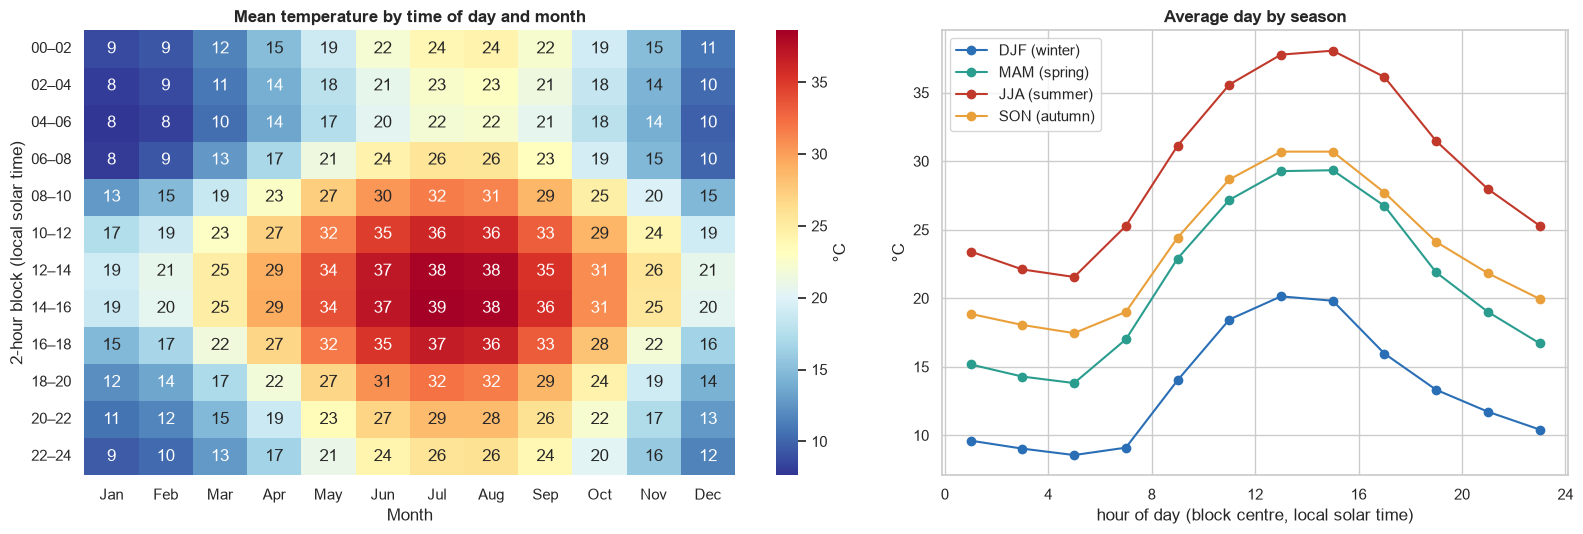

warmest block on average: 14:00–16:00 | coolest: 04:00–06:00
day–night range of the average day, by month (°C): {1: 11.4, 2: 12.5, 3: 14.5, 4: 15.8, 5: 16.4, 6: 16.9, 7: 16.6, 8: 16.1, 9: 15.1, 10: 13.1, 11: 11.8, 12: 10.9}


In [26]:
df["hour"] = df.index.hour
df["month"] = df.index.month
df["season"] = df.month.map(season_map)
diurnal_t = df.pivot_table(index="hour", columns="month", values="temp_mean", aggfunc="mean")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(diurnal_t, annot=True, fmt=".0f", cmap="RdYlBu_r", ax=ax1, cbar_kws={"label": "°C"},
            xticklabels=MONTHS, yticklabels=[f"{h:02d}–{h+2:02d}" for h in diurnal_t.index])
ax1.set(title="Mean temperature by time of day and month", xlabel="Month", ylabel="2-hour block (local solar time)")
for season, color in zip(ORDER, ["#2a6fb6", "#2a9d8f", "#c0392b", "#e9a03b"]):
    prof = df[df.season == season].groupby("hour").temp_mean.mean()
    ax2.plot(prof.index + 1, prof.values, "o-", color=color, label=season)
ax2.set_xticks(range(0, 25, 4)); ax2.set(title="Average day by season", xlabel="hour of day (block centre, local solar time)", ylabel="°C")
ax2.legend()
fig.tight_layout()
save(fig, "09_diurnal_temperature")

peak = df.groupby("hour").temp_mean.mean()
amp = diurnal_t.max() - diurnal_t.min()
print("warmest block on average:", f"{peak.idxmax():02d}:00–{peak.idxmax()+2:02d}:00", "| coolest:", f"{peak.idxmin():02d}:00–{peak.idxmin()+2:02d}:00")
print("day–night range of the average day, by month (°C):", amp.round(1).to_dict())

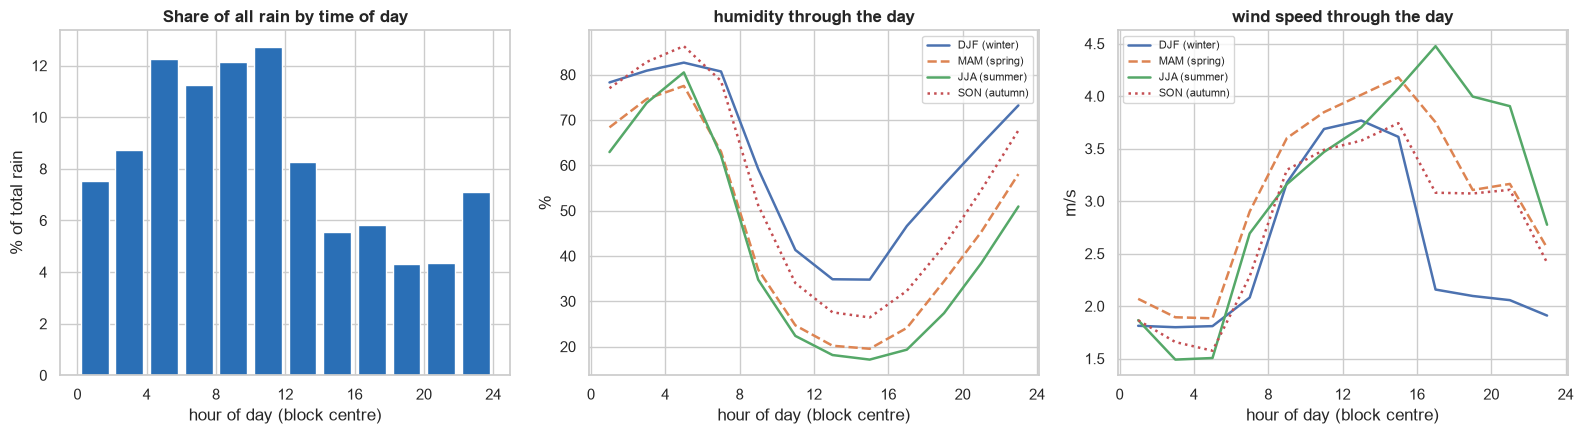

rain share by block (%): {0: 7.5, 2: 8.7, 4: 12.3, 6: 11.2, 8: 12.1, 10: 12.7, 12: 8.3, 14: 5.5, 16: 5.8, 18: 4.3, 20: 4.3, 22: 7.1}
humidity, average day: min 24 % at 14:00, max 82 % at 04:00
wind, average day: min 1.7 m/s at 04:00, max 3.9 m/s at 14:00


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
rain_by_hour = df.groupby("hour").precipitation.sum() / df.precipitation.sum() * 100
axes[0].bar(rain_by_hour.index + 1, rain_by_hour.values, width=1.6, color="#2a6fb6")
axes[0].set(title="Share of all rain by time of day", xlabel="hour of day (block centre)", ylabel="% of total rain")
for ax, col, unit, color in [(axes[1], "humidity", "%", "#2a9d8f"), (axes[2], "wind_speed", "m/s", "#6d4c41")]:
    for season, ls in zip(ORDER, ["-", "--", "-", ":"]):
        prof = df[df.season == season].groupby("hour")[col].mean()
        ax.plot(prof.index + 1, prof.values, ls, label=season, lw=1.8)
    ax.set(title=f"{col.replace('_', ' ')} through the day", xlabel="hour of day (block centre)", ylabel=unit)
    ax.legend(fontsize=8)
for ax in axes: ax.set_xticks(range(0, 25, 4))
fig.tight_layout()
save(fig, "10_diurnal_rain_humidity_wind")
print("rain share by block (%):", rain_by_hour.round(1).to_dict())
print("humidity, average day: min %.0f %% at %02d:00, max %.0f %% at %02d:00" % (
    df.groupby("hour").humidity.mean().min(), df.groupby("hour").humidity.mean().idxmin(),
    df.groupby("hour").humidity.mean().max(), df.groupby("hour").humidity.mean().idxmax()))
print("wind, average day: min %.1f m/s at %02d:00, max %.1f m/s at %02d:00" % (
    df.groupby("hour").wind_speed.mean().min(), df.groupby("hour").wind_speed.mean().idxmin(),
    df.groupby("hour").wind_speed.mean().max(), df.groupby("hour").wind_speed.mean().idxmax()))

**Interpretation (day–night cycle)**
- **The hottest time of day is 14:00–16:00** local solar time, and **the coolest is 04:00–06:00**, just before sunrise. The cycle is a clean, repeatable wave in every month.
- The **average day's range** goes from about 11 °C in December to 17 °C in June. In July the average day runs from 22 °C before dawn to 39 °C in mid-afternoon, so the clock matters about as much as the season.
- **Humidity mirrors temperature**: from 82 % at 04:00 down to 24 % at 14:00. **Wind** is calm at night (1.7 m/s at 04:00) and strongest in the afternoon (3.9 m/s at 14:00), as daytime heating mixes faster air down to the surface.
- **Rain falls more in the morning**: the 04:00–12:00 blocks hold about 48 % of all rain, and the evening (18:00–22:00) only about 9 %. This is a modelled (reanalysis) pattern, so it is best read as a tendency rather than a precise fact.

#### Rolling statistics: local level and volatility

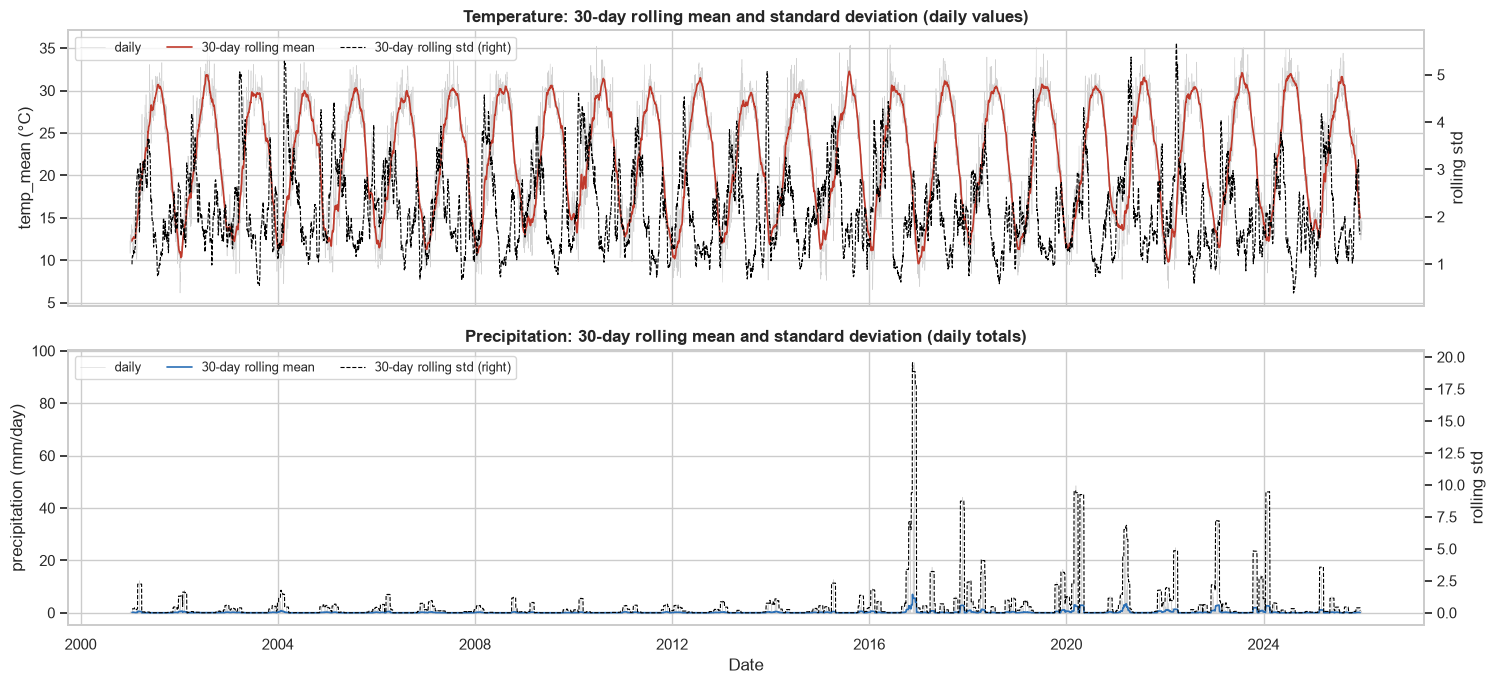

mean 30-day rolling std of daily temperature by month (°C):
 month
1     1.73
2     2.48
3     2.98
4     3.28
5     2.90
6     1.95
7     1.35
8     1.21
9     1.57
10    1.96
11    2.10
12    1.90


In [28]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for ax, col, color in [(axes[0], "temp_mean", "#c0392b"), (axes[1], "precipitation", "#2a6fb6")]:
    roll_mean = daily[col].rolling(30, center=True).mean()
    roll_std = daily[col].rolling(30, center=True).std()
    ax.plot(daily[col], color="lightgrey", lw=0.4, label="daily")
    ax.plot(roll_mean, color=color, lw=1.2, label="30-day rolling mean")
    ax.set_ylabel(f"{col} ({'°C' if col == 'temp_mean' else 'mm/day'})")
    ax2 = ax.twinx()
    ax2.plot(roll_std, color="black", lw=0.8, ls="--", label="30-day rolling std (right)")
    ax2.set_ylabel("rolling std"); ax2.grid(False)
    l1, l2 = ax.get_legend_handles_labels(), ax2.get_legend_handles_labels()
    ax.legend(l1[0] + l2[0], l1[1] + l2[1], loc="upper left", ncol=3, fontsize=9)
axes[0].set_title("Temperature: 30-day rolling mean and standard deviation (daily values)")
axes[1].set_title("Precipitation: 30-day rolling mean and standard deviation (daily totals)"); axes[1].set_xlabel("Date")
fig.tight_layout()
save(fig, "11_rolling_mean_std")
std_by_month = daily.temp_mean.rolling(30, center=True).std().groupby(daily.month).mean()
print("mean 30-day rolling std of daily temperature by month (°C):\n", std_by_month.round(2).to_string())

**Interpretation (rolling statistics)**
- The 30-day rolling mean traces the seasonal cycle, and its level is very similar from year to year.
- The **rolling standard deviation is itself seasonal (heteroscedastic)**. Averaged by month, it is highest in **April (3.3 °C)** and lowest in **August (1.2 °C)**. Spring weather is almost three times as variable as midsummer weather, so a model with one constant error variance would be over-confident in spring.
- For precipitation, the rolling mean and std stay at zero for months and spike together during storm clusters. The spikes are visibly larger and more frequent from 2016 on, which is the same rain-record break.

### 3.3 Decomposition and structure
#### Two-stage decomposition: yearly cycle (STL) + day–night cycle
The 2-hour series has **two** seasonal cycles: the year (4,380 readings) and the day (12 readings). A single MSTL fit with a 4,380-step period over 109,572 points ran for more than 10 minutes without finishing, and it would force one fixed daily shape on every month, although Cairo's day–night swing is larger in summer than in winter. The decomposition is therefore done in two additive stages:

1. **Yearly stage, STL on the 9,131 daily means** (period = 365, `robust=True`). This gives the trend and the yearly seasonal component. The seasonal window covers the whole record with `seasonal_deg=0`, which makes the yearly shape **strictly periodic**: any long-term warming then stays in the trend instead of leaking into “seasonality”, which is what the trend question needs.
2. **Day–night stage:** each reading minus its day's mean, averaged by **(month, 2-hour block)**. This is the typical day–night shape for each month.

`temperature = trend + yearly seasonal + day–night component + residual`, where the residual is the weather that the calendar and the clock do not explain.

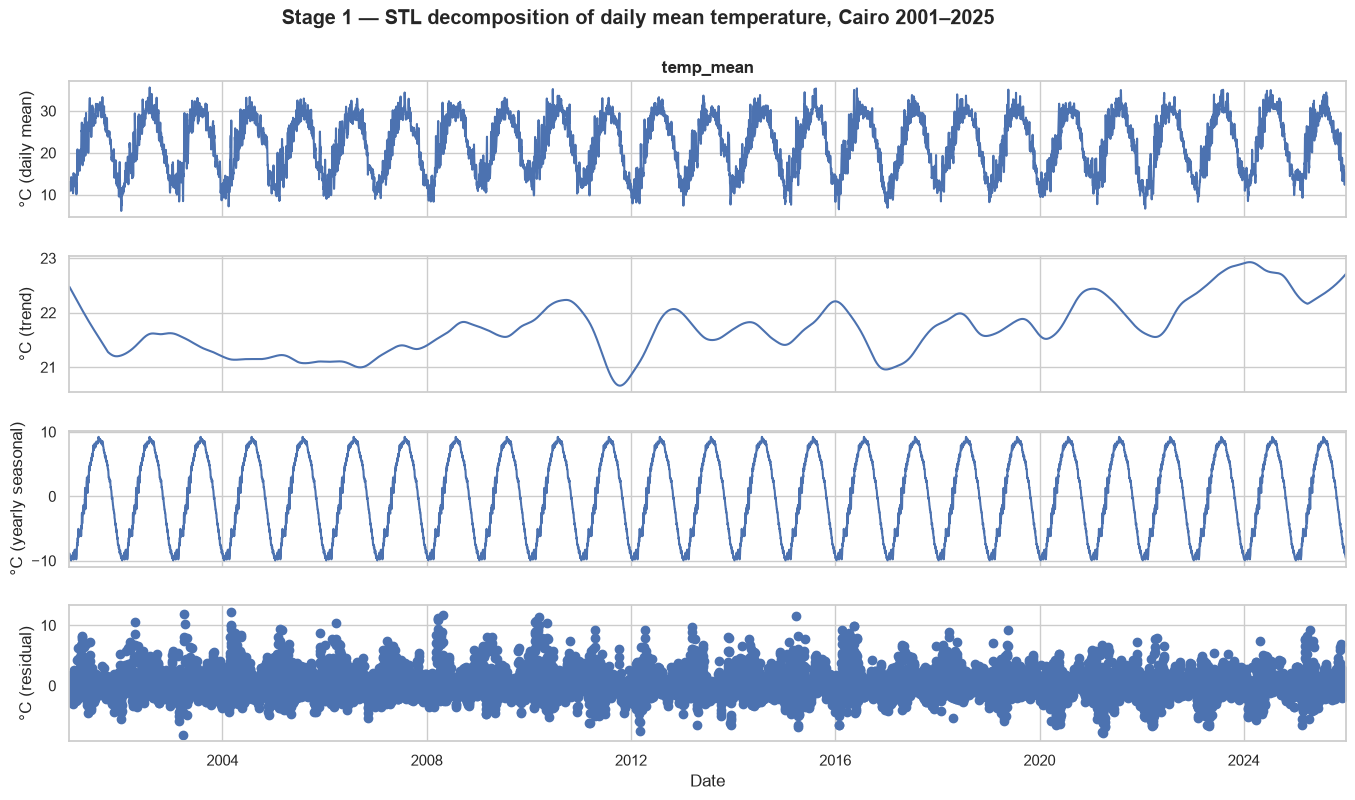

yearly seasonal amplitude: 19.2 °C | trend range: 20.66 → 22.93 °C
trend, first year mean 21.70 °C → last year mean 22.36 °C
daily residual std: 2.23 °C | strength of seasonality F_S = 0.89 | strength of trend F_T = 0.05


In [29]:
stl = STL(daily.temp_mean, period=365, seasonal=len(daily) + 1 - len(daily) % 2, seasonal_deg=0, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(15, 8)
for ax, lab in zip(fig.axes, ["°C (daily mean)", "°C (trend)", "°C (yearly seasonal)", "°C (residual)"]):
    ax.set_ylabel(lab)
fig.axes[-1].set_xlabel("Date")
fig.suptitle("Stage 1 — STL decomposition of daily mean temperature, Cairo 2001–2025", y=1.01, weight="bold")
save(fig, "12_stl_daily")

v = lambda s: np.nanvar(s)
F_S = max(0, 1 - v(stl.resid) / v(stl.seasonal + stl.resid))
F_T = max(0, 1 - v(stl.resid) / v(stl.trend + stl.resid))
print(f"yearly seasonal amplitude: {stl.seasonal.max() - stl.seasonal.min():.1f} °C | trend range: {stl.trend.min():.2f} → {stl.trend.max():.2f} °C")
print(f"trend, first year mean {stl.trend[:365].mean():.2f} °C → last year mean {stl.trend[-365:].mean():.2f} °C")
print(f"daily residual std: {stl.resid.std():.2f} °C | strength of seasonality F_S = {F_S:.2f} | strength of trend F_T = {F_T:.2f}")

variance of each component (°C²): {'trend': 0.24, 'yearly': 42.24, 'day–night': 26.93, 'residual': 6.21} | observed: 74.61
residual std: 2.49 °C | day–night component range: -8.3 → 8.6 °C


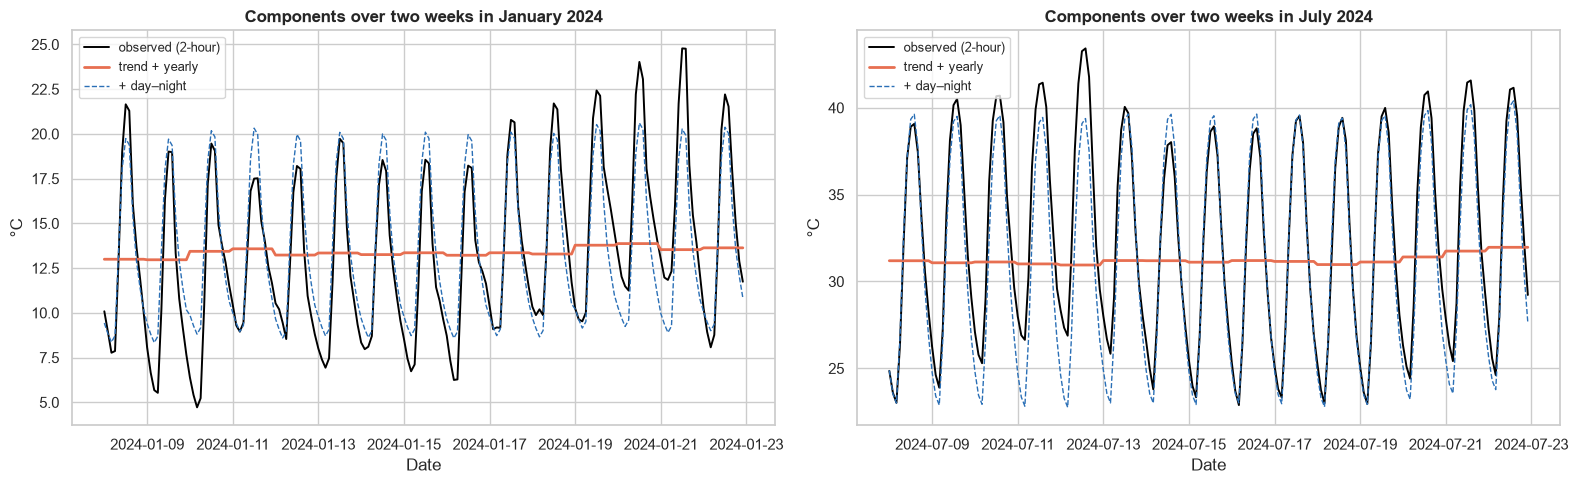

In [30]:
expand = lambda s: s.reindex(df.index, method="ffill")
day_mean = expand(daily.temp_mean)
dev = df.temp_mean - day_mean
diurnal_comp = dev.groupby([df.month, df.hour]).transform("mean")
comp = pd.DataFrame({
    "observed": df.temp_mean, "trend": expand(stl.trend), "yearly": expand(stl.seasonal),
    "day–night": diurnal_comp,
})
comp["residual"] = comp.observed - comp.trend - comp.yearly - comp["day–night"]

parts = comp[["trend", "yearly", "day–night", "residual"]]
print("variance of each component (°C²):", parts.var().round(2).to_dict(), "| observed:", round(comp.observed.var(), 2))
print(f"residual std: {comp.residual.std():.2f} °C | day–night component range: {diurnal_comp.min():.1f} → {diurnal_comp.max():.1f} °C")

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=False)
for ax, (start, label) in zip(axes, [("2024-01-08", "two weeks in January 2024"), ("2024-07-08", "two weeks in July 2024")]):
    w = comp.loc[start:(pd.Timestamp(start) + pd.Timedelta(days=14)).strftime("%Y-%m-%d")]
    ax.plot(w.observed, color="black", lw=1.4, label="observed (2-hour)")
    ax.plot(w.trend + w.yearly, color="#e76f51", lw=2, label="trend + yearly")
    ax.plot(w.trend + w.yearly + w["day–night"], color="#2a6fb6", lw=1, ls="--", label="+ day–night")
    ax.set(title=f"Components over {label}", ylabel="°C", xlabel="Date")
    ax.legend(fontsize=9, loc="upper left")
fig.tight_layout()
save(fig, "13_components_zoom")

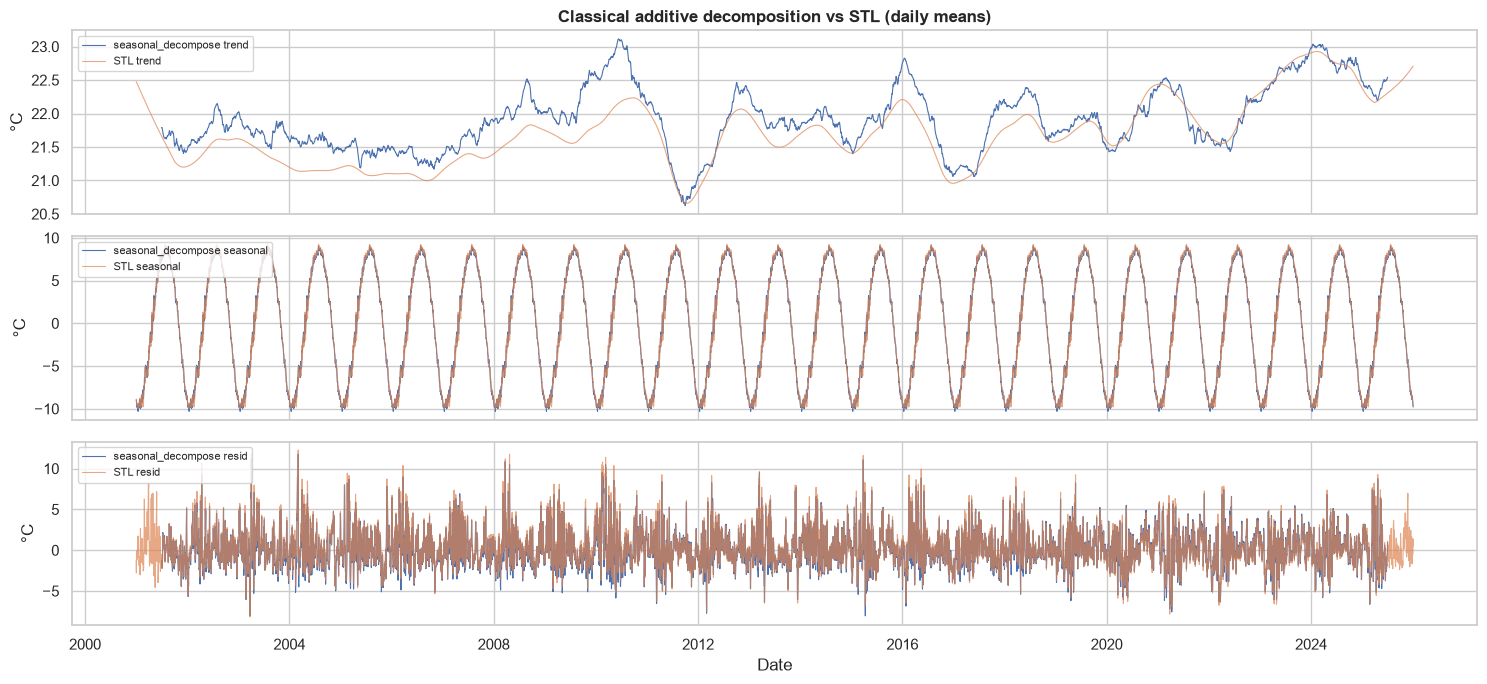

days without a trend value in seasonal_decompose: 364


In [31]:
classic = seasonal_decompose(daily.temp_mean, model="additive", period=365)
fig, axes = plt.subplots(3, 1, figsize=(15, 7), sharex=True)
for ax, c, name in zip(axes, [classic.trend, classic.seasonal, classic.resid], ["trend", "seasonal", "resid"]):
    ax.plot(c, lw=0.8, label=f"seasonal_decompose {name}")
    ax.plot(getattr(stl, name), lw=0.8, alpha=0.7, label=f"STL {name}")
    ax.set_ylabel("°C"); ax.legend(loc="upper left", fontsize=8)
axes[0].set_title("Classical additive decomposition vs STL (daily means)")
axes[-1].set_xlabel("Date")
fig.tight_layout()
save(fig, "14_classical_vs_stl")
print("days without a trend value in seasonal_decompose:", int(classic.trend.isna().sum()))

**Interpretation (decomposition)**
- **Variance split of the 2-hour temperature** (observed 74.6 °C²): yearly cycle **42.2** (57 %), day–night cycle **26.9** (36 %), residual weather **6.2** (8 %), and trend **0.24** (under 1 %). **The calendar and the clock together explain about 92 % of the variation**; only about 8 % is the "surprise" weather a forecaster actually has to predict.
- **Yearly stage:** seasonal amplitude about **19 °C** (peak to trough of the daily means), strength of seasonality **F_S = 0.89**, strength of trend F_T = 0.05. The trend line moves within 20.7–22.9 °C and is higher at the end (22.4 °C in the last year) than at the start (21.7 °C), consistent with the +0.28 °C/decade estimate.
- **Day–night stage:** the component spans −8.3 °C (pre-dawn) to +8.6 °C (afternoon). The two-week zooms show it reproduces the observed daily wave closely in July; in January the observed days vary more (cloudy vs clear nights), which is exactly what the residual captures.
- The classical `seasonal_decompose` agrees with STL on the daily shape, but its centred moving-average trend **loses half a year at each end (364 days)** and is not robust to outliers.

#### Autocorrelation (ACF) and partial autocorrelation (PACF)
Lags are in **2-hour steps**: lag 12 = one day, lag 84 = one week, lag 4,380 = one year.

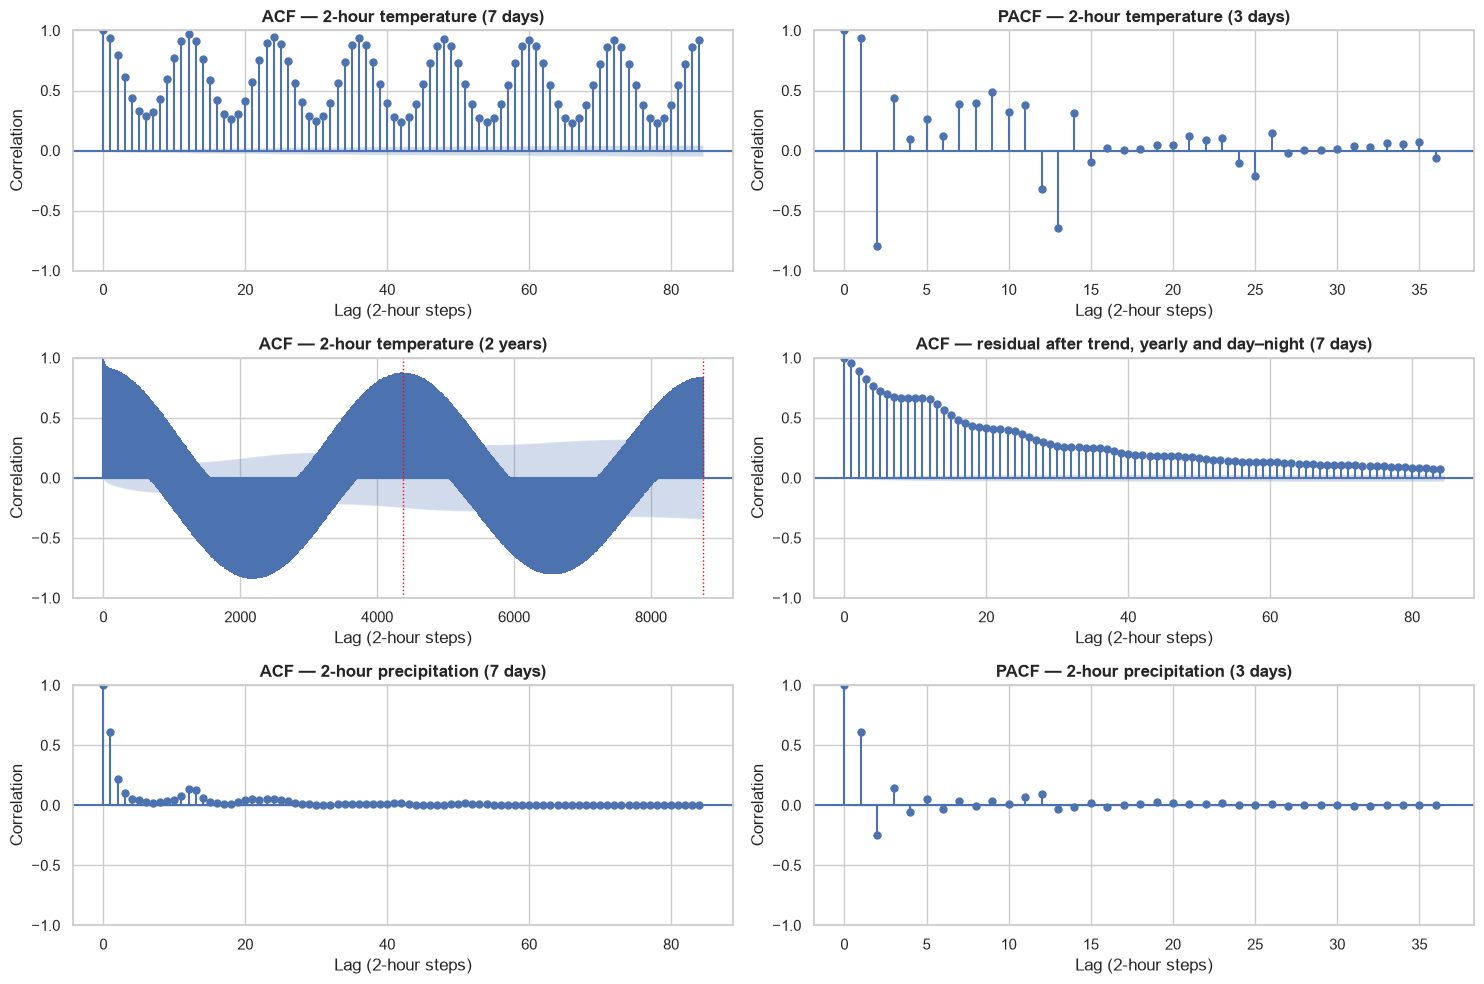

temperature ACF  lag1(2h)=0.94 lag6(12h)=0.29 lag12(1d)=0.97 lag84(7d)=0.92 lag2190(½y)=-0.84 lag4380(1y)=0.88
temperature PACF lag1=0.94 lag2=-0.79 lag3=0.44 lag12=-0.32
residual ACF     lag1=0.96 lag12(1d)=0.65 lag36(3d)=0.25 lag84(7d)=0.08
first lag where residual ACF < 0.1: 75 steps = 6.2 days
precipitation ACF lag1=0.61 lag6=0.02 lag12=0.14


In [32]:
fig, axes = plt.subplots(3, 2, figsize=(15, 10))
plot_acf(df.temp_mean, lags=84, ax=axes[0, 0], title="ACF — 2-hour temperature (7 days)")
plot_pacf(df.temp_mean, lags=36, ax=axes[0, 1], method="ywm", title="PACF — 2-hour temperature (3 days)")
plot_acf(df.temp_mean, lags=8760, ax=axes[1, 0], title="ACF — 2-hour temperature (2 years)", marker=None)
plot_acf(comp.residual, lags=84, ax=axes[1, 1], title="ACF — residual after trend, yearly and day–night (7 days)")
plot_acf(df.precipitation, lags=84, ax=axes[2, 0], title="ACF — 2-hour precipitation (7 days)")
plot_pacf(df.precipitation, lags=36, ax=axes[2, 1], method="ywm", title="PACF — 2-hour precipitation (3 days)")
for ax in axes.flat:
    ax.set_xlabel("Lag (2-hour steps)"); ax.set_ylabel("Correlation")
for lag in (4380, 8760):
    axes[1, 0].axvline(lag, color="red", ls=":", lw=1)
fig.tight_layout()
save(fig, "15_acf_pacf")

a_t = acf(df.temp_mean, nlags=8760, fft=True)
p_t = pacf(df.temp_mean, nlags=24, method="ywm")
a_r = acf(comp.residual, nlags=84, fft=True)
a_p = acf(df.precipitation, nlags=84, fft=True)
print("temperature ACF  lag1(2h)=%.2f lag6(12h)=%.2f lag12(1d)=%.2f lag84(7d)=%.2f lag2190(½y)=%.2f lag4380(1y)=%.2f"
      % (a_t[1], a_t[6], a_t[12], a_t[84], a_t[2190], a_t[4380]))
print("temperature PACF lag1=%.2f lag2=%.2f lag3=%.2f lag12=%.2f" % (p_t[1], p_t[2], p_t[3], p_t[12]))
print("residual ACF     lag1=%.2f lag12(1d)=%.2f lag36(3d)=%.2f lag84(7d)=%.2f" % (a_r[1], a_r[12], a_r[36], a_r[84]))
print("first lag where residual ACF < 0.1: %d steps = %.1f days" % (np.argmax(a_r < 0.1), np.argmax(a_r < 0.1) / 12))
print("precipitation ACF lag1=%.2f lag6=%.2f lag12=%.2f" % (a_p[1], a_p[6], a_p[12]))

**Interpretation (ACF/PACF)**
- With 2-hour steps, the **temperature ACF** is a wave: 0.94 at 2 hours, only 0.29 at 12 hours (day vs night), and **0.97 at 24 hours**. **The same time yesterday predicts the temperature better than 2 hours ago does.** Over two years the ACF shows the yearly cycle: −0.84 at half a year, +0.88 at one year.
- The **PACF** alternates strongly over the first few lags (0.94, −0.79, 0.44) and has a clear spike at lag 12 (one day). A model needs both short lags and a 24-hour seasonal lag.
- The **residual** (trend, yearly and day–night cycles removed) is still highly persistent: 0.96 at 2 hours, 0.65 after one day, and it only drops below 0.1 after about **6 days**. **Warm and cold spells last about a week**, so even after removing every cycle the residual is not white noise.
- **Precipitation** persists for a few hours (0.61 at lag 1, so rain in one block makes rain in the next likely) but is almost uncorrelated after 12 hours (0.02). Rain events in Cairo last hours, not days.

#### Stationarity: Augmented Dickey–Fuller (ADF), cross-checked with KPSS
The two tests have opposite null hypotheses. ADF's H₀ is a unit root (non-stationary); KPSS's H₀ is that the series is stationary. A series counts as stationary when ADF rejects (p < 0.05) **and** KPSS does not (p ≥ 0.05). For the 2-hour series the ADF lag search is capped at 48 steps (4 days) to keep the run short.

In [33]:
def stationarity(series, name, maxlag=None):
    s = series.dropna()
    adf_stat, adf_p, used_lag, *_ = adfuller(s, maxlag=maxlag, autolag="AIC", result_object=False)
    kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto", result_object=False)
    verdict = ("stationary" if adf_p < 0.05 and kpss_p >= 0.05 else
               "non-stationary" if adf_p >= 0.05 and kpss_p < 0.05 else
               "difference-stationary (ADF ✓, KPSS ✗)" if adf_p < 0.05 else "inconclusive (neither rejects)")
    return {"series": name, "n": len(s), "ADF stat": adf_stat, "ADF p": adf_p, "KPSS stat": kpss_stat,
            "KPSS p (≥0.1 = capped)": kpss_p, "verdict": verdict}

station = pd.DataFrame([
    stationarity(df.temp_mean, "2-hour temperature (raw)", maxlag=48),
    stationarity(daily.temp_mean, "daily mean temperature (raw)"),
    stationarity(daily.temp_mean - stl.seasonal, "daily temperature − yearly seasonal"),
    stationarity(comp.residual, "2-hour residual (all cycles + trend removed)", maxlag=48),
    stationarity(daily.temp_mean.diff(), "daily temperature, 1st difference"),
    stationarity(daily.temp_mean.diff(365), "daily temperature, seasonal difference (365)"),
    stationarity(daily.precipitation, "daily precipitation (raw)"),
]).set_index("series")
station

,n,ADF stat,ADF p,KPSS stat,KPSS p (≥0.1 = capped),verdict
series,,,,,,
2-hour temperature (raw),109572,-9.31,1.07e-15,0.11,0.10,stationary
daily mean temperature (raw),9131,-7.66,1.69e-11,0.04,0.10,stationary
daily temperature − yearly seasonal,9131,-12.35,5.76e-23,0.83,0.01,"difference-stationary (ADF ✓, KPSS ✗)"
2-hour residual (all cycles + trend removed),109572,-31.95,0.00e+00,0.59,0.02,"difference-stationary (ADF ✓, KPSS ✗)"
"daily temperature, 1st difference",9130,-11.90,5.57e-22,0.01,0.10,stationary
"daily temperature, seasonal difference (365)",8766,-13.69,1.36e-25,0.05,0.10,stationary
daily precipitation (raw),9131,-14.85,1.79e-27,1.89,0.01,"difference-stationary (ADF ✓, KPSS ✗)"


In [34]:
# The tests answer “does the series wander away for good?”. A second question matters for modeling:
# does the mean stay the same over time? Compare the mean of the same calendar month across the record.
by_period = daily.groupby([(daily.index.year - 2001) // 5 * 5 + 2001, "month"]).temp_mean.mean().unstack()
by_period.index = [f"{y}–{y+4}" for y in by_period.index]
by_period.columns = MONTHS
by_period["year"] = by_period.mean(axis=1)
by_period.round(1)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,year
2001–2005,12.2,13.4,17.0,20.8,25.2,27.9,30.1,29.7,27.3,23.4,18.6,13.8,21.6
2006–2010,12.6,14.2,17.6,21.2,24.9,28.9,29.7,30.0,27.3,24.0,18.8,14.6,22.0
2011–2015,12.2,13.5,16.8,20.8,25.6,28.1,29.7,30.0,27.6,23.4,18.7,13.9,21.7
2016–2020,11.2,13.9,16.9,20.8,25.6,29.2,30.3,29.9,27.8,23.9,18.6,13.8,21.8
2021–2025,13.1,12.8,16.3,21.3,25.7,29.2,31.0,30.8,28.4,24.1,19.8,15.0,22.3


**Interpretation (stationarity)**
- **Raw temperature (2-hour and daily) now passes both tests**: ADF rejects a unit root (p ≈ 1e-15 and 1e-11) and KPSS does not reject stationarity. With 6 years the result was inconclusive; with 25 complete cycles the tests can see that the series always returns to the same seasonal pattern and never wanders off. **This does not mean its mean is constant.** The series is *cyclostationary*: its mean depends on the month and the hour (12 °C on a January morning, 39 °C on a July afternoon). The tests answer "does it drift away for good?", not "is the mean the same at every moment?".
- **Temperature minus the yearly seasonal component**: ADF rejects a unit root, but KPSS rejects stationarity (p = 0.01). Once the season is removed, **the slow warming trend** becomes the dominant feature of the series, and KPSS detects the mean that is not constant. The 5-year table above shows it directly: the annual mean rises from 21.6 °C (2001–05) to 22.3 °C (2021–25), with the largest increases from July to December (about +0.7 to +1.2 °C) and none in February–March.
- **First difference and seasonal difference (365 days)**: both tests agree these are **stationary**. Differencing removes both the cycle and the trend.
- **Daily precipitation**: ADF rejects a unit root, but KPSS rejects stationarity (p = 0.01). This is the **2016 break** in the rain record seen as a statistic: the series' level is different before and after.

**What this implies for modeling.** Temperature should be modelled with **explicit seasonality at two periods**: day-of-year and hour-of-day terms (for example sin/cos features, or a climatology by month × hour), plus a **slow trend** (a linear term or one difference). The residual's week-long memory and the strong 24-hour autocorrelation justify short lags (1–3 steps) plus a lag of 12 steps (same time yesterday). The season-dependent variance argues for checking errors by month. Precipitation should not be modelled across the 2016 break as if it were one series; use 2016–2025 only, or rain occurrence instead of amounts, or bias-correct first.

### 3.4 Relationships and anomalies
#### Correlation between variables

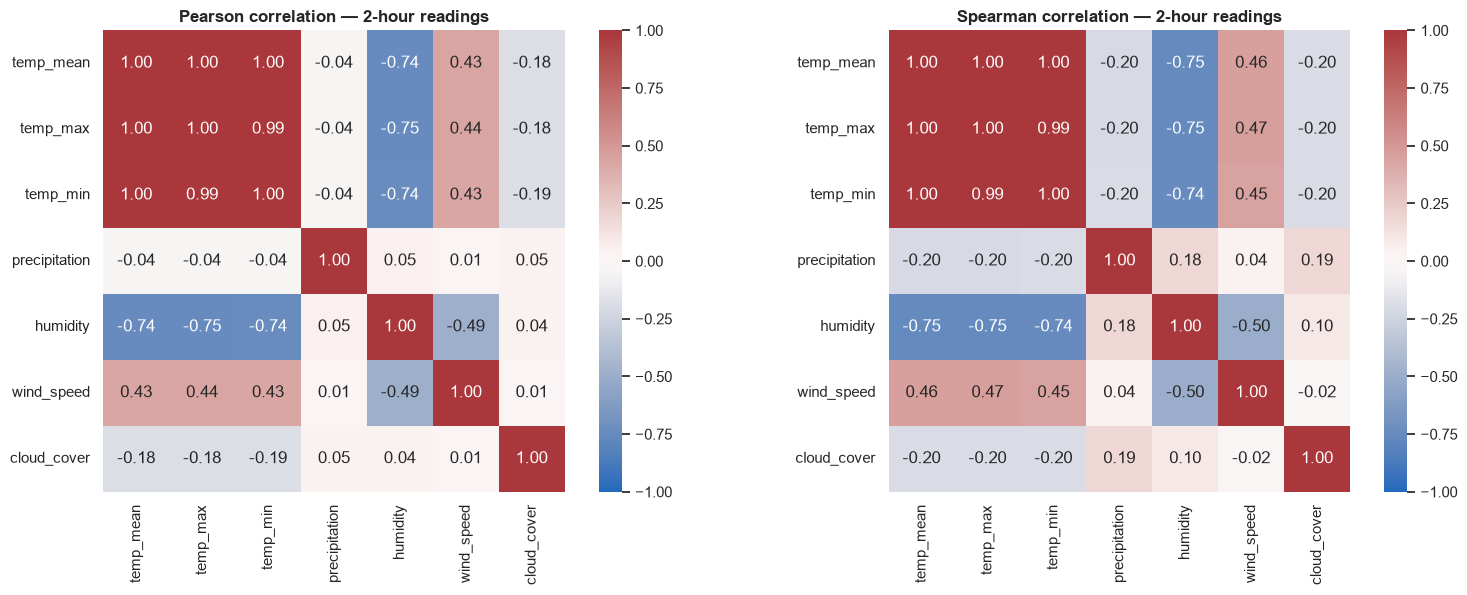

temp vs rain, 2-hour   Spearman ρ = -0.20 (p = 0.0e+00) | Pearson r = -0.04
temp vs rain, daily    Spearman ρ = -0.38 (p = 0.0e+00) | Pearson r = -0.10
temp vs rain, monthly  Spearman ρ = -0.73 (p = 1.9e-50) | Pearson r = -0.29
daily Spearman with rain: {'temp_mean': -0.38, 'temp_max': -0.41, 'temp_min': -0.33, 'precipitation': 1.0, 'humidity': 0.43, 'wind_speed': -0.02, 'cloud_cover': 0.29}


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[VARS].corr(method=method), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax, square=True)
    ax.set_title(f"{method.title()} correlation — 2-hour readings")
fig.tight_layout()
save(fig, "16_correlation")

monthly = daily[VARS].resample("ME").agg({**{c: "mean" for c in VARS}, "precipitation": "sum"})
for label, a, b in [("2-hour", df.temp_mean, df.precipitation), ("daily", daily.temp_mean, daily.precipitation),
                    ("monthly", monthly.temp_mean, monthly.precipitation)]:
    r, p = stats.spearmanr(a, b)
    print(f"temp vs rain, {label:8s} Spearman ρ = {r:+.2f} (p = {p:.1e}) | Pearson r = {np.corrcoef(a, b)[0, 1]:+.2f}")
print("daily Spearman with rain:", daily[VARS].corr("spearman")["precipitation"].round(2).to_dict())

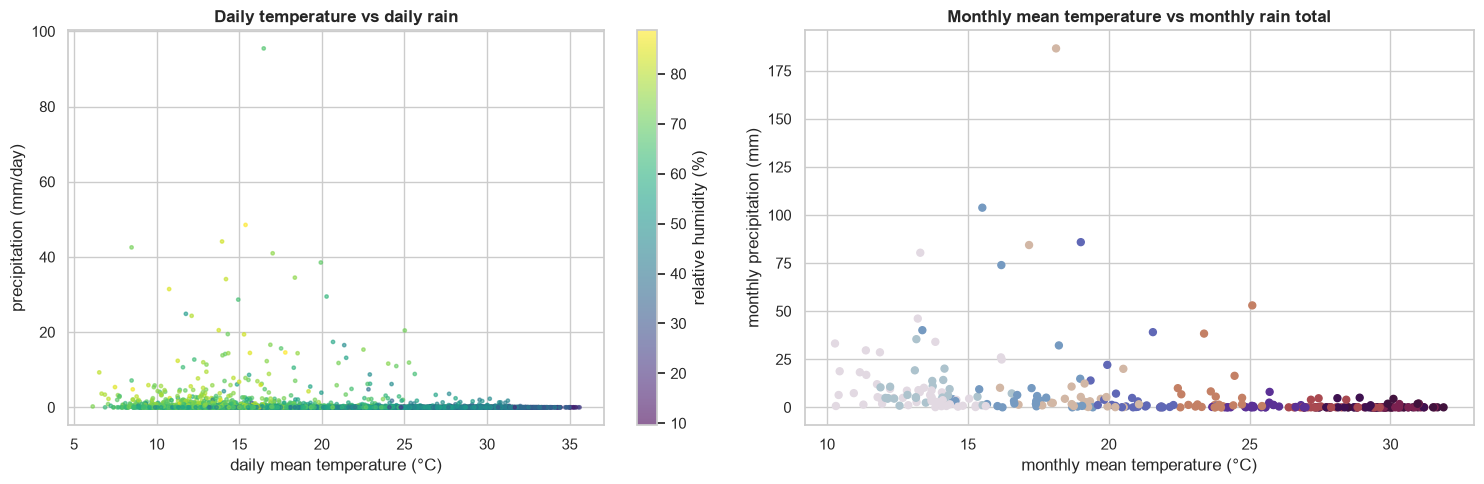

In [36]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
sc = ax1.scatter(daily.temp_mean, daily.precipitation, c=daily.humidity, cmap="viridis", s=6, alpha=0.6)
fig.colorbar(sc, ax=ax1, label="relative humidity (%)")
ax1.set(title="Daily temperature vs daily rain", xlabel="daily mean temperature (°C)", ylabel="precipitation (mm/day)")
ax2.scatter(monthly.temp_mean, monthly.precipitation, c=monthly.index.month, cmap="twilight", s=25)
ax2.set(title="Monthly mean temperature vs monthly rain total", xlabel="monthly mean temperature (°C)", ylabel="monthly precipitation (mm)")
fig.tight_layout()
save(fig, "17_temp_vs_rain")

**Interpretation (relationships)**
- **Temperature and rain are negatively related, and the link grows with aggregation**: Spearman ρ = −0.20 for 2-hour readings, −0.38 for days and **−0.73 for months**. Pearson is much weaker (−0.04, −0.10, −0.29) because rain is mostly zeros with a few large values. The relationship is seasonal: rain belongs to the cool half of the year, but most cool hours and days are still dry.
- **Humidity is the variable most tied to temperature** (Pearson −0.74 on 2-hour readings, −0.64 on daily means). Within a day, humidity falls as the air warms (relative humidity is relative to the warmer air's capacity). Humidity is also the variable most linked to rain (daily Spearman +0.43), followed by cloud cover (+0.29). Wind is nearly independent of rain.
- The three temperature columns of a block are almost identical (correlation above 0.99), as expected for max/mean/min of two hours. A model should use one of them.

#### Outlier detection: rolling windows vs a global threshold
A global threshold compares every reading with the whole 25-year spread, which is dominated by the yearly and day–night cycles, so it can only flag summer afternoons and winter nights. A rolling, *local* threshold on the residual (trend, yearly and day–night cycles removed) asks a better question: *is this reading unusual for this time of year and this time of day?* The window is 30 days (360 readings).

In [37]:
resid = comp.residual
W = 30 * PER_DAY
roll = resid.rolling(W, center=True, min_periods=W // 2)
mu, sd = roll.mean(), roll.std()
z_roll = (resid - mu) / sd
q1, q3 = roll.quantile(0.25), roll.quantile(0.75)
iqr = q3 - q1
out = pd.DataFrame({
    "temp_mean": df.temp_mean, "resid": resid, "z_roll": z_roll,
    "flag_rolling_z": z_roll.abs() > 4,
    "flag_rolling_iqr": (resid < q1 - 3 * iqr) | (resid > q3 + 3 * iqr),
    "flag_global_z": np.abs(stats.zscore(df.temp_mean)) > 3,
})
g_iqr = stats.iqr(df.temp_mean)
out["flag_global_iqr"] = ~df.temp_mean.between(df.temp_mean.quantile(.25) - 1.5 * g_iqr, df.temp_mean.quantile(.75) + 1.5 * g_iqr)
flag_any = out.flag_rolling_z | out.flag_rolling_iqr
print("readings flagged:\n", out.filter(like="flag").sum().to_string())
print("both rolling flags:", int((out.flag_rolling_z & out.flag_rolling_iqr).sum()), "| either:", int(flag_any.sum()))

# Consecutive flagged readings belong to one weather event: group them by calendar day
events = out[flag_any].copy()
events["date"] = events.index.date
ev = events.groupby("date").agg(readings=("resid", "size"), peak_temp=("temp_mean", "max"),
                                largest_anomaly=("resid", lambda s: s.loc[s.abs().idxmax()]))
ev["direction"] = np.where(ev.largest_anomaly > 0, "warmer than usual", "colder than usual")
print(f"distinct days with flagged readings: {len(ev)} | warm: {(ev.direction == 'warmer than usual').sum()} | cold: {(ev.direction == 'colder than usual').sum()}")
print("flagged days per month:", pd.Series(pd.to_datetime(ev.index).month).value_counts().sort_index().to_dict())
ev.sort_values("largest_anomaly", key=abs, ascending=False).head(10).round(2)

readings flagged:
 flag_rolling_z      29
flag_rolling_iqr    89
flag_global_z        0
flag_global_iqr      0
both rolling flags: 26 | either: 92
distinct days with flagged readings: 40 | warm: 36 | cold: 4
flagged days per month: {1: 5, 2: 3, 3: 4, 4: 2, 5: 4, 6: 5, 7: 2, 8: 3, 9: 4, 10: 6, 11: 1, 12: 1}


,readings,peak_temp,largest_anomaly,direction
date,,,,
2003-04-04,2,39.67,14.05,warmer than usual
2015-03-27,10,37.86,13.40,warmer than usual
2006-03-23,3,36.06,13.03,warmer than usual
2007-05-03,2,28.27,11.52,warmer than usual
2019-02-05,3,29.06,11.44,warmer than usual
2007-05-02,1,28.56,11.03,warmer than usual
2024-04-24,4,41.52,10.60,warmer than usual
2012-03-11,2,34.19,10.55,warmer than usual
2021-11-29,2,33.34,10.41,warmer than usual


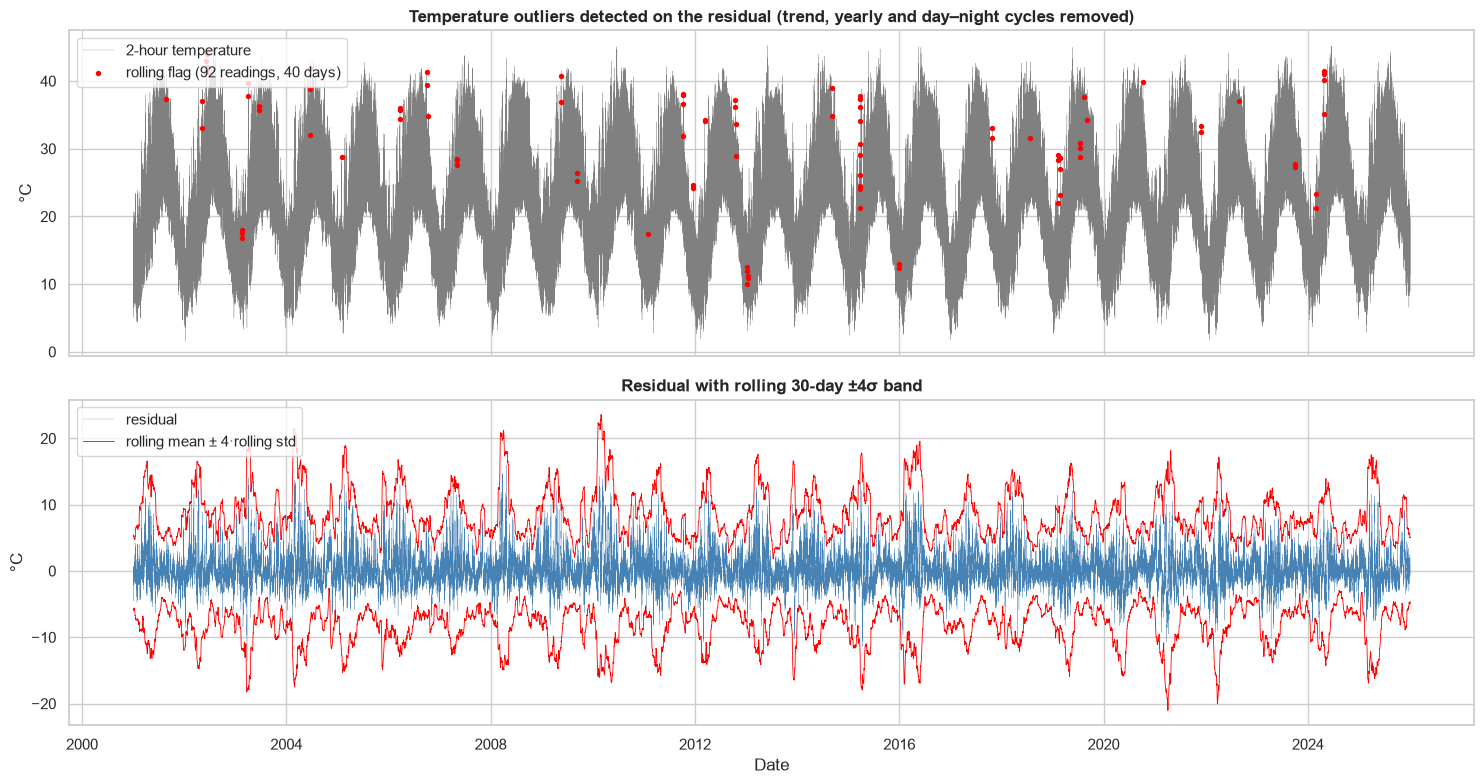

In [38]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
axes[0].plot(df.temp_mean, color="grey", lw=0.2, label="2-hour temperature")
f = out[flag_any]
axes[0].scatter(f.index, f.temp_mean, color="red", s=8, zorder=3, label=f"rolling flag ({len(f)} readings, {len(ev)} days)")
axes[0].set(title="Temperature outliers detected on the residual (trend, yearly and day–night cycles removed)", ylabel="°C")
axes[0].legend(loc="upper left")
axes[1].plot(resid, color="steelblue", lw=0.2, label="residual")
axes[1].plot(mu + 4 * sd, color="red", lw=0.6, label="rolling mean ± 4·rolling std")
axes[1].plot(mu - 4 * sd, color="red", lw=0.6)
axes[1].set(title="Residual with rolling 30-day ±4σ band", ylabel="°C", xlabel="Date"); axes[1].legend(loc="upper left")
fig.tight_layout()
save(fig, "18_outliers_temperature")

In [39]:
# Precipitation: rolling thresholds are meaningless for a mostly-zero series, so extremes are judged
# against the wet-day distribution (daily totals, 99th percentile) instead.
wet = daily.loc[daily.precipitation >= 0.1, "precipitation"]
p99 = wet.quantile(0.99)
extreme_rain = daily.loc[daily.precipitation > p99, ["precipitation", "temp_mean", "humidity", "cloud_cover"]]
print(f"wet-day 99th percentile = {p99:.1f} mm/day -> {len(extreme_rain)} extreme rain days")
print("wettest 2-hour block: %.1f mm at %s" % (df.precipitation.max(), df.precipitation.idxmax()))
extreme_rain.sort_values("precipitation", ascending=False).round(1)

wet-day 99th percentile = 29.0 mm/day -> 10 extreme rain days
wettest 2-hour block: 46.1 mm at 2016-11-30 08:00:00


,precipitation,temp_mean,humidity,cloud_cover
datetime,,,,
2016-11-30,95.5,16.5,66.7,21.0
2020-03-12,48.5,15.4,88.5,97.1
2017-11-21,44.1,14.0,82.7,46.2
2024-01-31,42.5,8.5,71.9,34.0
2020-04-25,41.0,17.0,75.1,52.4
2016-11-22,38.5,19.9,68.9,84.3
2016-11-03,34.5,18.4,75.0,29.5
2023-01-24,34.1,14.2,81.6,15.3
2024-02-02,31.4,10.8,84.3,42.4


**Interpretation (outliers)**
- **Global thresholds flag nothing**: 0 readings by global z-score and 0 by global IQR. Every reading lies within the 25-year range of Cairo's normal yearly and daily cycle, so a 30 °C reading on a January night would also pass.
- **Rolling, local detectors on the residual** flag **92 readings on 40 distinct days** (29 readings with |rolling z| > 4, 89 outside the 3·IQR rolling fence, 26 by both). Thresholds are stricter than for daily data (4σ instead of 3σ) because 109,572 readings would otherwise produce many false alarms by chance alone.
- **36 of the 40 days are warm spikes and only 4 are cold.** The largest are spring heat events: **+14.1 °C above normal on 4 April 2003** (39.7 °C), +13.4 °C on 27 March 2015 (37.9 °C, flagged for a whole day: 10 readings), +13.0 °C on 23 March 2006. Hot desert winds (*khamsin*) typically bring this kind of sudden spring heat.
- All flagged readings are **physically plausible weather** and are **kept**. They are real extremes a model should be allowed to miss, not errors to delete.
- **Extreme rain:** 10 days exceed the wet-day 99th percentile (29 mm/day). **12 March 2020 (48.5 mm)** coincides with the severe storm that hit Egypt that day. But the wettest day on record, **95.5 mm on 30 November 2016**, with 46 mm in a single 2-hour block and only 21 % daily cloud cover, is far beyond anything Cairo's stations normally report. **All 10 extreme days fall in 2016 or later**, which points to the rain-record break below.

#### Suspicious values: likely sensor or API errors, not weather

In [40]:
step = df.temp_mean.diff().abs()
suspicious = pd.DataFrame([
    ("negative precipitation", int((df.precipitation < 0).sum())),
    ("block temp_min > temp_max", int((df.temp_min > df.temp_max).sum())),
    ("temp_mean outside [temp_min, temp_max]", int(((df.temp_mean < df.temp_min - 1e-9) | (df.temp_mean > df.temp_max + 1e-9)).sum())),
    ("2-hour jump in temperature > 10 °C", int((step > 10).sum())),
    ("temperature outside Cairo's plausible range (-2 … 50 °C)", int(((df.temp_min < -2) | (df.temp_max > 50)).sum())),
    ("humidity outside 0–100 %", int((~df.humidity.between(0, 100)).sum())),
    ("cloud cover outside 0–100 %", int((~df.cloud_cover.between(0, 100)).sum())),
    ("negative wind speed", int((df.wind_speed < 0).sum())),
    ("leftover fill value -999", int((df[VARS] == -999).sum().sum())),
    ("day with rain ≥ 1 mm but daily cloud cover < 5 %", int(((daily.precipitation >= 1) & (daily.cloud_cover < 5)).sum())),
], columns=["check", "rows flagged"])
print(f"largest 2-hour temperature change: {step.max():.1f} °C at {step.idxmax()}")
print(df.loc[step > 10, ["temp_mean", "humidity", "wind_speed", "cloud_cover"]].assign(change=df.temp_mean.diff()[step > 10]).round(1))
print(df.loc["2014-06-04 12:00":"2014-06-04 20:00", ["temp_mean", "humidity", "wind_speed", "cloud_cover"]].round(1))
suspicious

largest 2-hour temperature change: 11.4 °C at 2014-06-04 18:00:00
                     temp_mean  humidity  wind_speed  cloud_cover  change
datetime                                                                 
2007-06-25 08:00:00       36.0      19.0         3.2         77.3    10.0
2014-06-04 18:00:00       29.3      31.5         7.4         99.7   -11.4
                     temp_mean  humidity  wind_speed  cloud_cover
datetime                                                         
2014-06-04 12:00:00       43.8       7.9         7.3         87.8
2014-06-04 14:00:00       43.9       7.4         6.8         98.5
2014-06-04 16:00:00       40.7       9.1         6.3        100.0
2014-06-04 18:00:00       29.3      31.5         7.4         99.7
2014-06-04 20:00:00       26.4      41.8         5.1         98.6


,check,rows flagged
0,negative precipitation,0
1,block temp_min > temp_max,0
2,"temp_mean outside [temp_min, temp_max]",0
3,2-hour jump in temperature > 10 °C,2
4,temperature outside Cairo's plausible range (-...,0
5,humidity outside 0–100 %,0
6,cloud cover outside 0–100 %,0
7,negative wind speed,0
8,leftover fill value -999,0
9,day with rain ≥ 1 mm but daily cloud cover < 5 %,11


#### Is the rain record consistent over time? (homogeneity check)
A climate record should not change character overnight. The annual rain totals are split at every possible year, and the split with the largest difference is tested.

strongest break: 2016 | annual rain median 23 mm before vs 125 mm from 2016 on (5.4×), Mann–Whitney p = 4e-05
days with ≥ 10 mm: 2 in 15 years before vs 38 in 10 years after
temperature over the same split: 21.81 → 22.10 °C (no matching jump)


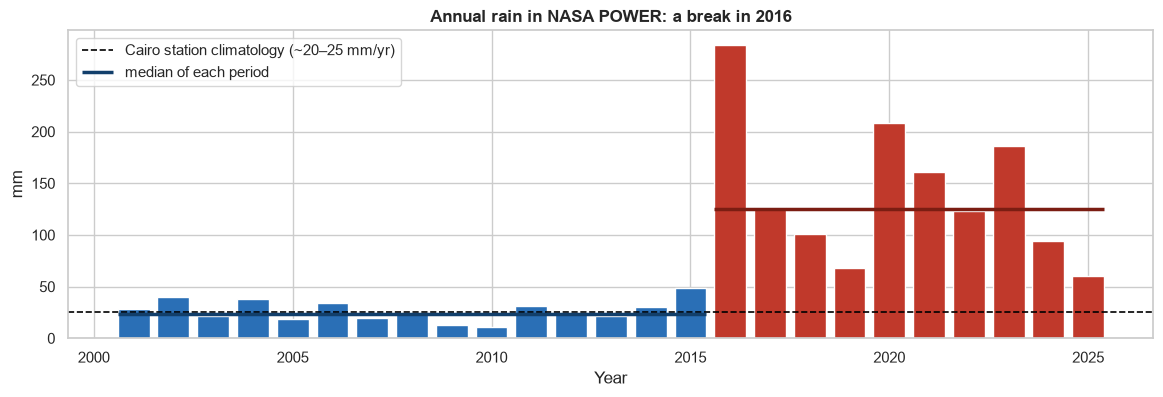

In [41]:
ann_rain = annual["total rain (mm)"]
split = max(range(2004, 2023), key=lambda y: abs(np.log(ann_rain[ann_rain.index >= y]).mean() - np.log(ann_rain[ann_rain.index < y]).mean()))
before, after = ann_rain[ann_rain.index < split], ann_rain[ann_rain.index >= split]
heavy = (daily.precipitation >= 10).groupby(daily.index.year).sum()
mw = stats.mannwhitneyu(before, after)
t_before = annual.loc[annual.index < split, "mean temp (°C)"].mean()
t_after = annual.loc[annual.index >= split, "mean temp (°C)"].mean()
print(f"strongest break: {split} | annual rain median {before.median():.0f} mm before vs {after.median():.0f} mm from {split} on "
      f"({after.median() / before.median():.1f}×), Mann–Whitney p = {mw.pvalue:.1g}")
print(f"days with ≥ 10 mm: {int(heavy[heavy.index < split].sum())} in {len(before)} years before vs {int(heavy[heavy.index >= split].sum())} in {len(after)} years after")
print(f"temperature over the same split: {t_before:.2f} → {t_after:.2f} °C (no matching jump)")
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(ann_rain.index, ann_rain, color=np.where(ann_rain.index < split, "#2a6fb6", "#c0392b"))
ax.axhline(25, color="black", ls="--", lw=1.2, label="Cairo station climatology (~20–25 mm/yr)")
ax.hlines([before.median(), after.median()], [ann_rain.index.min() - 0.4, split - 0.4], [split - 0.6, ann_rain.index.max() + 0.4],
          colors=["#123f6b", "#7b1d12"], lw=2.5, label="median of each period")
ax.set(title=f"Annual rain in NASA POWER: a break in {split}", xlabel="Year", ylabel="mm")
ax.legend(loc="upper left")
save(fig, "19_rain_break")

In [42]:
# Plausibility of the precipitation *level*: compare with Cairo's long-term station climatology.
# Station climatologies for Cairo commonly put annual rainfall at roughly 20-25 mm; we use the upper end (25 mm)
# so the ratio below is, if anything, an underestimate of the bias.
CLIMATE_NORMAL_MM = 25
ratio = annual["total rain (mm)"] / CLIMATE_NORMAL_MM
print(f"NASA POWER annual rain: median {annual['total rain (mm)'].median():.0f} mm, range {annual['total rain (mm)'].min():.0f}–{annual['total rain (mm)'].max():.0f} mm")
print(f"ratio to the station normal: median {ratio.median():.1f}×, range {ratio.min():.1f}–{ratio.max():.1f}×")
print("years below the station normal:", list(annual.index[annual['total rain (mm)'] < CLIMATE_NORMAL_MM]))
print(f"ratio by period: {split - 15}–{split - 1} median {before.median() / CLIMATE_NORMAL_MM:.1f}× | "
      f"{split}–2025 median {after.median() / CLIMATE_NORMAL_MM:.1f}× (range {after.min() / CLIMATE_NORMAL_MM:.1f}–{after.max() / CLIMATE_NORMAL_MM:.1f}×)")
print("wettest day on record: %.1f mm on %s" % (daily.precipitation.max(), daily.precipitation.idxmax().date()))

NASA POWER annual rain: median 38 mm, range 11–284 mm
ratio to the station normal: median 1.5×, range 0.5–11.4×
years below the station normal: [2003, 2005, 2007, 2008, 2009, 2010, 2012, 2013]
ratio by period: 2001–2015 median 0.9× | 2016–2025 median 5.0× (range 2.4–11.4×)
wettest day on record: 95.5 mm on 2016-11-30


**Interpretation (suspicious values and data quality)**
- **No impossible values were found**: 0 negative rain, 0 blocks with min > max, 0 values outside physical ranges, 0 leftover -999 values. This is expected for a reanalysis product, which is model-generated and physically consistent by construction.
- **Two 2-hour temperature jumps above 10 °C.** The largest, **−11.4 °C on 4 June 2014** (43.9 °C at 14:00 to 29.3 °C at 18:00), arrives with cloud cover jumping to 100 %, wind at 7.4 m/s and humidity rising from 7 % to 32 %. That is the signature of a thunderstorm or dust-storm outflow, so it is **kept as real weather**.
- **11 days with at least 1 mm of rain but under 5 % daily cloud cover.** Rain comes from MERRA-2 and cloud from the CERES satellite product, and the two don't always agree. These days are **flagged and kept**; if cloud cover is used as a predictor, treat them with caution.
- **The rain record is not homogeneous (the main data-quality finding).** The annual totals break sharply in **2016**: the median is **23 mm a year for 2001–2015**, about the same as Cairo's station climatology (~20–25 mm, ratio 0.9×), but **125 mm a year for 2016–2025** (5.4× higher, 2.4–11.4× the station normal; Mann–Whitney p = 4e-5). Days with ≥ 10 mm go from 2 in fifteen years to 38 in ten years. **Temperature shows no jump at the same time** (21.8 → 22.1 °C, in line with gradual warming). A real climate shift of this size in one year is not plausible, so the most likely cause is a change in the data behind the precipitation product. The pre-2016 values match station records, which also explains why the 6-year version of this analysis (2020–2025) found inflated rainfall: it only saw the post-break period. **Handling:** the values are kept unchanged in the clean CSV (no silent "fix"), the break is documented, rain conclusions are stated in relative terms (timing, seasonality, occurrence), and any model of rain amounts should either use one side of the break or bias-correct against station data.

## Written summary

**Region and time range.** Cairo, Egypt (30.04 °N, 31.24 °E), 1 January 2001 to 31 December 2025: 25 complete years, 219,144 hourly values reduced to **109,572 readings at 12 a day** (2-hour blocks). 2001 is the first year NASA POWER serves hourly data, and 2025 the last complete year.

**API and why.** NASA POWER Hourly API (`/api/temporal/hourly/point`, `community=AG`, local solar time). It is free, needs no key, covers any coordinate, and serves hourly data from 2001. 25 yearly requests, all answered on the first try with no rate limit. Twelve readings a day keep the day–night cycle visible with even spacing at half the size of the hourly data; 25 years make the trend question answerable.

**Main temporal patterns.** Temperature follows two strong cycles: the **year** (January 12.3 °C, July 30.2 °C) and the **day** (warmest 14:00–16:00, coolest 04:00–06:00, an average swing of 15 °C). Together with the trend they explain about **92 %** of all variation; the remaining weather persists for about a week. Spring is the most volatile season (rolling std 3.3 °C in April vs 1.2 °C in August), with sudden heat spikes of up to +14 °C. **Cairo has warmed by about +0.28 °C per decade (p = 0.03)**, driven by nights (+0.42 °C/decade) more than days (+0.13, not significant), so the day–night swing is shrinking (−0.30 °C/decade). Rain falls almost only from October to April, mostly in the morning, 90 % of days are dry, and wetter months are cooler (monthly Spearman ρ = −0.73).

**Is the series stationary?** Raw temperature passes ADF and KPSS, because with 25 cycles it always returns to the same seasonal pattern, but its mean depends on the month and hour (it is cyclostationary), so it is not stationary in the sense a model needs. With the season removed, KPSS detects the warming trend. First or seasonal differencing makes both tests agree it is stationary. A model therefore needs explicit yearly and daily seasonality plus a trend or difference term, with short lags and a 24-hour lag.

**Data quality issues and how they were handled.** The hourly series is complete (no gaps, duplicates, missing values or -999), and the missing-value strategy with imputation flags stays in the pipeline for future pulls. Units come from the API metadata, and the 2-hour aggregation conserves rain and daily extremes. No impossible values were found; 40 days with unusual temperatures (36 heat spikes) and one 11 °C storm drop were checked and kept as real weather. Two issues were flagged rather than "fixed": 11 days with rain but almost no cloud (a disagreement between data products), and above all a **break in the rain record in 2016**, when annual totals jump from about 23 mm (matching Cairo's stations) to about 125 mm, with no matching change in temperature. Rain amounts after 2016 should not be trusted without correction, and rain conclusions are stated in relative terms.